# Solar Filament Segmentation 2026 — v4: two-stage **detector + refiner**

Competition: https://www.kaggle.com/competitions/filament-segmentation-2026 · Metric: **PQ** (match = IoU > 0.5)

### Why a different design
Your diagnostics showed (1) train PQ ≈ val PQ (underfitting) and (2) **148 of ~3,800 ground-truth filament pairs overlap**. A semantic U-Net assigns each pixel to one mask, so it can never output two overlapping instances, and any blob covering two GT filaments counts as a *merge*. An **instance** model *can* output overlapping masks — **but Kaggle rejects submissions in which predicted masks of an image overlap**, so overlaps are resolved at the end (each shared pixel goes to the higher-scoring filament).

### Pipeline (same family as the weights you shared)
I inspected the uploaded `final_detector.pt` / `final_refiner.pt` without executing anything from them (they are plain state dicts). The layer names/shapes show:

| File | What it is |
|---|---|
| `final_detector.pt` | torchvision **Mask R-CNN, ResNet-50-FPN (v2)**, 2 classes (background + filament), ~46M params |
| `final_refiner.pt` | **U-Net with a ResNet-18 encoder**, 3-channel input, 1-channel output, ~14M params |

This notebook **does not load those weights**. It trains the same *kind* of pipeline on your data from public COCO / ImageNet weights:

```
2048² image ──► Mask R-CNN (boxes + coarse 28×28 masks, overlaps allowed)
                      │ for every candidate filament:
                      ▼
          crop window around it ─► refiner U-Net ─► fine mask
          channels = [CLAHE image, coarse mask, other filaments' coarse masks]
                      │
                      ▼
      score filter + mask-IoU NMS + min-area  ─► one RLE per filament ─► submission.csv
```
Mask R-CNN's 28×28 masks are far too coarse for thin filaments — the refiner re-segments each one at higher resolution.

### Built to survive Colab disconnects
Everything that is slow is **saved to Google Drive** (`WORK_DIR`) and **skipped / resumed** on the next run:

| Slow thing | Saved as | What happens after a reconnect |
|---|---|---|
| Detector training | `det_resume.pt` (every epoch) + `det_best.pt` | resumes from the last finished epoch; if finished, skipped |
| Refiner training | `ref_resume.pt` + `ref_best.pt` | same |
| Detections + refinements (val / test) | `cache_*.pkl` (keyed to the checkpoints) | loaded in seconds; changing thresholds, NMS, `make_disjoint` never re-runs the networks |
| Tuned config | `best_cfg.json` | restored by the "restore" cell |

Flags in the config cell: `RETRAIN_DET`, `RETRAIN_REF` (start over), `RECOMPUTE_CACHE` (ignore saved caches).
**After a reconnect:** re-run the setup cells top to bottom (they are fast; training cells detect the saved checkpoints and skip), then the *restore* cell, then only the stage you are working on.
Tip: put your Kaggle token in Colab **Secrets** (key icon, name `KAGGLE_API_TOKEN`) so you are not prompted every session.

**Run order:** top to bottom. First do a smoke test (`SMOKE_TEST = True`, a few minutes), then set it to `False`.
**Not yet tested on a GPU with the real data** (I could only test the logic on synthetic data) — if a cell errors, paste the traceback.

> Never paste your Kaggle token into a cell (the repo must be public). This notebook asks for it with a hidden prompt.

## 0. Runtime + installs

In [1]:
import torch, torchvision
print("torch", torch.__version__, "| torchvision", torchvision.__version__)
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-> Runtime > Change runtime type > GPU")


torch 2.11.0+cu130 | torchvision 0.26.0+cu130
CUDA: True Tesla T4


In [2]:
!pip install -q pycocotools kaggle


## 1. Get the data

In [3]:
import os, getpass
from pathlib import Path

if "KAGGLE_API_TOKEN" not in os.environ and not Path("/root/.kaggle/kaggle.json").exists():
    try:                                    # Colab Secrets (left sidebar, key icon): survives reconnects, never stored in the notebook
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    except Exception:
        os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Paste your Kaggle API token: ")   # hidden, not stored


Paste your Kaggle API token: ··········


In [4]:
if not Path("/content/comp_data/.done").exists():
    !kaggle competitions download -c filament-segmentation-2026 -p /content/comp_data
    !cd /content/comp_data && unzip -q -o filament-segmentation-2026.zip
    Path("/content/comp_data/.done").touch()
!find /content/comp_data -maxdepth 3 -type d | sort | head -20


100% 671M/671M [00:31<00:00, 22.4MB/s]

/content/comp_data
/content/comp_data/MAGFiLO_1.0_Kaggle_2026
/content/comp_data/MAGFiLO_1.0_Kaggle_2026/test
/content/comp_data/MAGFiLO_1.0_Kaggle_2026/test/test_images
/content/comp_data/MAGFiLO_1.0_Kaggle_2026/train
/content/comp_data/MAGFiLO_1.0_Kaggle_2026/train/train_images


## 2. Config

In [5]:
import random, json, glob, math
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from collections import defaultdict
from pycocotools import mask as maskUtils

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
PREPROC = "clahe"           # "clahe" (default) | "raw" | "msr" | "msr_clahe". Changing it means retraining everything; each choice gets its own work folder.
SMOKE_TEST = False            # True = tiny fast run to check the pipeline end-to-end

IMG_SIZE = 2048
VAL_FRACTION = 0.15
VAL_SUBSET_N = 40             # val images used for monitoring + tuning
FULL_VAL_MAX = 200            # cap for the final full-val evaluation

# ---- stage 1: detector (Mask R-CNN)
DET_ARCH = "v2"               # "v2" (better, heavier) or "v1" (FrozenBN, most robust at tiny batch)
DET_CROP = 1024               # training crop (native resolution, no resizing)
DET_BATCH = 2                 # lower to 1 if you hit CUDA OOM
DET_EPOCHS = 8
DET_LR = 1e-4
DET_POS_CROP_PROB = 0.8
DET_MIN_PIX = 20              # drop instances with fewer pixels left inside a crop
DET_MIN_SCORE = 0.2           # keep candidates down to this score (tuned later)
DET_NMS = 0.6                 # box NMS inside the detector (mask-IoU NMS is tuned later)
DET_MAX_DETS = 100

# ---- stage 2: refiner (U-Net / ResNet-18)
REF_SIZE = 384                # square window is resized to this (divisible by 32)
REF_K = 6                     # instances sampled per image per step
REF_BATCH_IMAGES = 4
REF_EPOCHS = 10
REF_LR = 3e-4
REF_MARGIN = (16, 40)         # random window margin (px) while training
REF_MARGIN_INFER = 28
CTX_SCORE = 0.5               # candidates above this score act as "other filaments" context

if SMOKE_TEST:
    DET_EPOCHS, REF_EPOCHS, VAL_SUBSET_N, FULL_VAL_MAX = 1, 1, 4, 4

USE_AMP = torch.cuda.is_available()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:                                         # persistent storage: survives Colab reconnects
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/filament_work" + ("" if PREPROC == "clahe" else f"_{PREPROC}"))
except ImportError:
    WORK_DIR = Path("./filament_work" + ("" if PREPROC == "clahe" else f"_{PREPROC}"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
RETRAIN_DET = False           # True = delete saved detector checkpoints and train from scratch
RETRAIN_REF = False
RECOMPUTE_CACHE = False       # True = ignore saved detection/refinement caches
MASK_ADJUST = 0               # grow (+) / shrink (-) final masks by this many px; set by the grow/shrink experiment
USE_YOLO = False              # True = pool YOLO11-seg passes too (set by the YOLO cell)
USE_DET2 = False              # True = pool a second detector's passes too (set by the detector-2 cell)
USE_REF2 = False              # True = use ref2_best.pt (refiner trained on real detector outputs); set automatically by the tuned config
print("work dir:", WORK_DIR, "| saved files:", sorted(p.name for p in WORK_DIR.glob("*"))[:20])


Mounted at /content/drive
work dir: /content/drive/MyDrive/filament_work | saved files: ['best_cfg.json', 'cache_pool2_test_1793273871_4.pkl', 'cache_pool2_val_1793273871_4.pkl', 'cache_pool3_test_1793276999_4.pkl', 'cache_pool3_val_1793276999_4.pkl', 'cache_pool_test_1793263529_4.pkl', 'cache_pool_val_1793263529_4.pkl', 'cache_traindet_1793263529.pkl', 'cache_tune_1793263529_1793266266.pkl', 'cache_tune_1793263560_1793271399.pkl', 'cache_valall_1793263529_1793271374_coarse.pkl', 'cache_valfull_1793263529_1793266266_ref_0.4_15.pkl', 'det2_best.pt', 'det2_resume.pt', 'det_best.pt', 'det_resume.pt', 'ref2_best.pt', 'ref2_resume.pt', 'ref_best.pt', 'ref_resume.pt']


In [6]:
DATA_ROOT = Path("/content/comp_data")
for c in [DATA_ROOT] + list(DATA_ROOT.glob("*/")) + list(DATA_ROOT.glob("*/*/")):
    if (c / "train").exists():
        DATA_ROOT = c; break
TRAIN_IMG_DIR = DATA_ROOT / "train" / "train_images"
TEST_IMG_DIR = DATA_ROOT / "test" / "test_images"
TRAIN_ANN_PATH = sorted((DATA_ROOT / "train").glob("*.json"))[0]
test_files = sorted(glob.glob(str(TEST_IMG_DIR / "*.jp*g")))
test_stems = [Path(p).stem for p in test_files]
print("DATA_ROOT:", DATA_ROOT, "| annotations:", TRAIN_ANN_PATH.name, "| test imgs:", len(test_stems))


DATA_ROOT: /content/comp_data/MAGFiLO_1.0_Kaggle_2026 | annotations: MAGFiLO_1.0_Annotations_kaggle2026_train.json | test imgs: 180


## 3. Parse annotations (one annotation = one filament instance)

In [7]:
with open(TRAIN_ANN_PATH) as f:
    ann_raw = json.load(f)
images_list, anns_list = ann_raw["images"], ann_raw["annotations"]
id_to_stem = {im["id"]: Path(im["file_name"]).stem for im in images_list}

image_to_insts = defaultdict(list)       # stem -> [segmentation, ...] one per filament
for a in anns_list:
    seg, stem = a.get("segmentation"), id_to_stem.get(a["image_id"])
    if stem is None or not seg: continue
    if isinstance(seg, dict): image_to_insts[stem].append(seg)
    else:
        polys = [p for p in seg if isinstance(p, list) and len(p) >= 6]
        if polys: image_to_insts[stem].append(polys)

def img_exists(s): return any((TRAIN_IMG_DIR / f"{s}{e}").exists() for e in (".jpeg", ".jpg", ".png"))
all_stems = sorted(s for s in set(id_to_stem.values()) if img_exists(s))
n_inst = [len(image_to_insts.get(s, [])) for s in all_stems]
print(f"images {len(all_stems)} | with filaments {sum(n > 0 for n in n_inst)} | filaments {sum(n_inst)} | per image mean {np.mean(n_inst):.1f} max {max(n_inst)}")


images 707 | with filaments 707 | filaments 8199 | per image mean 11.6 max 58


In [8]:
def resolve_img_path(img_dir, stem):
    for ext in (".jpeg", ".jpg", ".png"):
        p = img_dir / f"{stem}{ext}"
        if p.exists(): return p
    raise FileNotFoundError(stem)

def clahe_uint8(img):
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)

def _blur(a, sigma):
    """Gaussian blur; very large sigmas are computed on a downsampled copy (same result, much faster)."""
    f = 1 if sigma <= 20 else (4 if sigma <= 100 else 8)
    if f == 1: return cv2.GaussianBlur(a, (0, 0), sigma)
    h, w = a.shape
    small = cv2.resize(a, (w // f, h // f), interpolation=cv2.INTER_AREA)
    return cv2.resize(cv2.GaussianBlur(small, (0, 0), sigma / f), (w, h), interpolation=cv2.INTER_LINEAR)

def msr_uint8(img, sigmas=(15, 80, 250), clip=(1.0, 99.0)):
    """Multi-Scale Retinex for a grayscale H-alpha disk: mean over scales of log(I) - log(local illumination).
    The illumination estimate is blurred only INSIDE the solar disk (normalised convolution), so the limb does not create halos."""
    a = img.astype(np.float32) + 1.0
    t = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0]
    disk = cv2.morphologyEx((img > t).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8)).astype(np.float32)
    out = np.zeros_like(a)
    for s in sigmas:
        illum = _blur(a * disk, s) / np.maximum(_blur(disk, s), 1e-3)
        out += np.log(a) - np.log(np.maximum(illum, 1.0))
    out /= len(sigmas)
    lo, hi = np.percentile(out[disk > 0], clip) if disk.any() else (float(out.min()), float(out.max()))
    return (np.clip((out - lo) / max(hi - lo, 1e-6), 0, 1) * disk * 255).astype(np.uint8)

def preprocess(img):
    """Single switch for the whole pipeline (train, val, test, every model): set PREPROC in the config cell."""
    if PREPROC == "raw": return img
    if PREPROC == "clahe": return clahe_uint8(img)
    if PREPROC == "msr": return msr_uint8(img)
    if PREPROC == "msr_clahe": return clahe_uint8(msr_uint8(img))
    raise ValueError(f"unknown PREPROC {PREPROC!r}")

def load_image_clahe(path):
    """(name kept for compatibility) grayscale image -> preprocess() according to PREPROC. Identical for every stage and split."""
    return preprocess(np.array(Image.open(path).convert("L")))

def seg_to_mask(seg, h=IMG_SIZE, w=IMG_SIZE):
    if isinstance(seg, dict):
        rle = maskUtils.frPyObjects(seg, h, w) if isinstance(seg["counts"], list) else dict(seg)
        if isinstance(rle["counts"], str): rle["counts"] = rle["counts"].encode("utf-8")
    else:
        rle = maskUtils.merge(maskUtils.frPyObjects(seg, h, w))
    return maskUtils.decode(rle).astype(np.uint8)

def bbox_of(m):
    """(x0, y0, x1, y1) of a binary mask, or None if empty."""
    ys = np.flatnonzero(m.any(1))
    if len(ys) == 0: return None
    xs = np.flatnonzero(m.any(0))
    return int(xs[0]), int(ys[0]), int(xs[-1]) + 1, int(ys[-1]) + 1

def window_for_box(box, margin, min_side=96):
    """Square window centred on the box. Returns (x0, y0, side)."""
    x0, y0, x1, y1 = box
    L = int(round(max(max(x1 - x0, y1 - y0) + 2 * margin, min_side)))
    return int(round((x0 + x1) / 2 - L / 2)), int(round((y0 + y1) / 2 - L / 2)), L

def crop_resize(arr, wx0, wy0, L, size):
    """2-D array -> (size,size) crop of the square window (zero padded outside the image)."""
    H, W = arr.shape[:2]
    out = np.zeros((L, L), arr.dtype)
    sx0, sy0, sx1, sy1 = max(wx0, 0), max(wy0, 0), min(wx0 + L, W), min(wy0 + L, H)
    if sx1 > sx0 and sy1 > sy0:
        out[sy0 - wy0:sy1 - wy0, sx0 - wx0:sx1 - wx0] = arr[sy0:sy1, sx0:sx1]
    return cv2.resize(out, (size, size), interpolation=cv2.INTER_AREA if L > size else cv2.INTER_LINEAR)

def paste_window(prob, wx0, wy0, L, H, W):
    """(size,size) window prediction -> (y0, y1, x0, x1, patch) in image coordinates."""
    big = cv2.resize(prob, (L, L), interpolation=cv2.INTER_LINEAR)
    sx0, sy0, sx1, sy1 = max(wx0, 0), max(wy0, 0), min(wx0 + L, W), min(wy0 + L, H)
    return sy0, sy1, sx0, sx1, big[sy0 - wy0:sy1 - wy0, sx0 - wx0:sx1 - wx0]

_gt_rles = {}
def get_gt_rles(stem):
    if stem not in _gt_rles:
        _gt_rles[stem] = [maskUtils.encode(np.asfortranarray(seg_to_mask(s))) for s in image_to_insts.get(stem, [])]
    return _gt_rles[stem]

def pq_image(gt_rles, pred_rles, thr=0.5):
    G, P = len(gt_rles), len(pred_rles)
    z = dict(iou_sum=0.0, tp=0, fp=P, fn=G, frag=0, merge=0)
    if G == 0 or P == 0: return z
    iou = np.array(maskUtils.iou(pred_rles, gt_rles, [0] * G)).reshape(P, G)
    pairs = sorted(((iou[p, g], p, g) for p in range(P) for g in range(G) if iou[p, g] > thr), reverse=True)
    used_p, used_g, s = set(), set(), 0.0
    for v, p, g in pairs:
        if p in used_p or g in used_g: continue
        used_p.add(p); used_g.add(g); s += float(v)
    tp = len(used_g)
    aP = np.array(maskUtils.area(pred_rles), float); aG = np.array(maskUtils.area(gt_rles), float)
    inter = iou * (aP[:, None] + aG[None, :]) / (1 + iou)
    frag = int(((inter / np.maximum(aG[None, :], 1) > 0.1).sum(0) >= 2).sum())
    merge = int(((inter / np.maximum(aP[:, None], 1) > 0.1).sum(1) >= 2).sum())
    return dict(iou_sum=s, tp=tp, fp=P - tp, fn=G - tp, frag=frag, merge=merge)


### Quick look: instances (colored) on one image, and how much GT filaments overlap

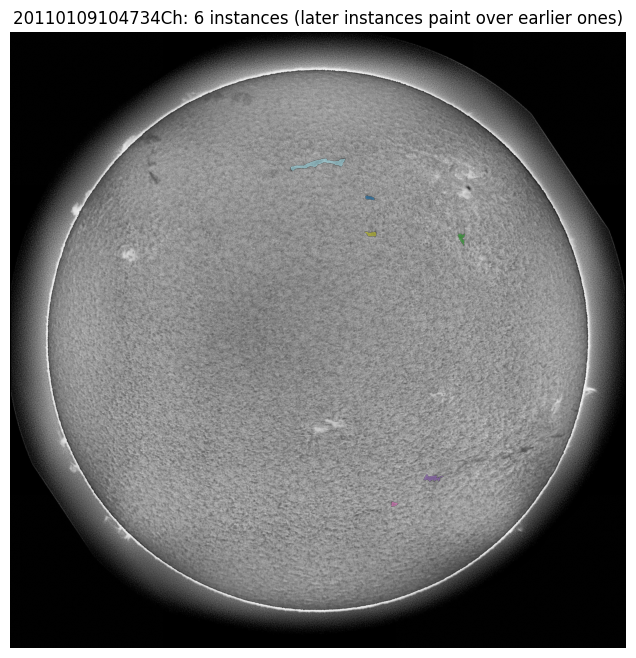

GT pairs: 4119 | overlapping: 199 | of those, smaller one >90% inside the other: 86


In [9]:
s0 = next(s for s in all_stems if len(image_to_insts.get(s, [])) >= 4)
img0 = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s0))
lbl = np.zeros(img0.shape, np.int32)
for i, seg in enumerate(image_to_insts[s0], 1): lbl[seg_to_mask(seg) > 0] = i
plt.figure(figsize=(8, 8)); plt.imshow(img0, cmap="gray"); plt.imshow(np.ma.masked_equal(lbl, 0), cmap="tab20", alpha=0.6)
plt.title(f"{s0}: {lbl.max()} instances (later instances paint over earlier ones)"); plt.axis("off"); plt.show()

ov = nested = pairs = 0
for s in random.Random(0).sample(all_stems, min(40, len(all_stems))):
    ms = [seg_to_mask(sg) for sg in image_to_insts.get(s, [])]
    for i in range(len(ms)):
        for j in range(i + 1, len(ms)):
            pairs += 1; inter = int((ms[i] & ms[j]).sum())
            if inter:
                ov += 1; nested += inter / max(1, min(ms[i].sum(), ms[j].sum())) > 0.9
print(f"GT pairs: {pairs} | overlapping: {ov} | of those, smaller one >90% inside the other: {nested}")


## 4. Train / val split (grouped by month)

In [10]:
def group_key(stem): return stem[:6]            # YYYYMM
groups = sorted(set(group_key(s) for s in all_stems))
if len(groups) < 8:
    group_key = lambda stem: stem[:8]; groups = sorted(set(group_key(s) for s in all_stems))
random.Random(SEED).shuffle(groups)
val_groups = set(groups[:max(1, int(len(groups) * VAL_FRACTION))])
train_stems = [s for s in all_stems if group_key(s) not in val_groups]
val_stems = [s for s in all_stems if group_key(s) in val_groups]
if SMOKE_TEST:
    train_stems = [s for s in train_stems if image_to_insts.get(s)][:12]
    val_stems = [s for s in val_stems if image_to_insts.get(s)][:6]
    test_stems = test_stems[:3]
sweep_stems = sorted(random.Random(SEED).sample(sorted(val_stems), min(VAL_SUBSET_N, len(val_stems))))
mon_stems = sweep_stems[:min(15, len(sweep_stems))]          # fast per-epoch monitoring
print(f"train {len(train_stems)} | val {len(val_stems)} | tuning subset {len(sweep_stems)} | monitor {len(mon_stems)}")


train 620 | val 87 | tuning subset 40 | monitor 15


## 5. Stage 1 — Mask R-CNN detector

Fine-tuned from **public COCO weights** (allowed as external model). Trained on native-resolution 1024² crops (no resizing, so thin filaments stay thin), 3 channels = the CLAHE image repeated. Overlapping GT instances are kept as separate masks.

In [11]:
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import (maskrcnn_resnet50_fpn_v2, maskrcnn_resnet50_fpn,
                                          MaskRCNN_ResNet50_FPN_V2_Weights, MaskRCNN_ResNet50_FPN_Weights)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

class DetDataset(Dataset):
    def __init__(self, stems, per_image=1):
        self.items = [s for s in stems for _ in range(per_image)]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        stem = self.items[i]
        img = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, stem)); H, W = img.shape
        masks = [seg_to_mask(s) for s in image_to_insts.get(stem, [])]
        y0 = random.randint(0, H - DET_CROP); x0 = random.randint(0, W - DET_CROP)
        if masks and random.random() < DET_POS_CROP_PROB:
            ys, xs = np.nonzero(np.maximum.reduce(masks)[::4, ::4])
            if len(ys):
                k = random.randrange(len(ys))
                y0 = int(np.clip(ys[k] * 4 - random.randint(64, DET_CROP - 64), 0, H - DET_CROP))
                x0 = int(np.clip(xs[k] * 4 - random.randint(64, DET_CROP - 64), 0, W - DET_CROP))
        sl = (slice(y0, y0 + DET_CROP), slice(x0, x0 + DET_CROP))
        rot, flip = random.randint(0, 3), random.random() < 0.5
        def tf(a):
            a = np.rot90(a, rot)
            return np.ascontiguousarray(a[:, ::-1] if flip else a)
        im = tf(img[sl]); ms = [tf(m[sl]) for m in masks]
        if random.random() < 0.5:
            im = np.clip(im.astype(np.float32) * random.uniform(0.85, 1.15) + random.uniform(-10, 10), 0, 255).astype(np.uint8)
        keep, boxes = [], []
        for m in ms:
            if m.sum() >= DET_MIN_PIX:
                keep.append(m); boxes.append(bbox_of(m))
        x = torch.from_numpy(im.astype(np.float32) / 255.0).unsqueeze(0).repeat(3, 1, 1)
        tgt = dict(boxes=torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                   labels=torch.ones(len(keep), dtype=torch.int64),
                   masks=torch.from_numpy(np.stack(keep)) if keep else torch.zeros((0, DET_CROP, DET_CROP), dtype=torch.uint8))
        return x, tgt

def det_collate(batch): return tuple(zip(*batch))

def build_detector(pretrained=True, arch=None):
    arch = arch or DET_ARCH
    kw = dict(min_size=DET_CROP, max_size=DET_CROP, box_detections_per_img=DET_MAX_DETS)
    if arch == "v2":
        m = maskrcnn_resnet50_fpn_v2(weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT if pretrained else None, **kw)
    else:
        m = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT if pretrained else None, **kw)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 2)
    m.roi_heads.mask_predictor = MaskRCNNPredictor(m.roi_heads.mask_predictor.conv5_mask.in_channels, 256, 2)
    return m

def det_train_mode(det):
    det.train(); det.transform.min_size = (DET_CROP,); det.transform.max_size = DET_CROP
    for m in det.backbone.modules():                   # batch of 2 is too small to update BatchNorm statistics
        if isinstance(m, nn.BatchNorm2d): m.eval()

def det_infer_mode(det):
    det.eval(); det.transform.min_size = (IMG_SIZE,); det.transform.max_size = IMG_SIZE   # full image, scale 1.0
    det.roi_heads.score_thresh = DET_MIN_SCORE; det.roi_heads.nms_thresh = DET_NMS; det.roi_heads.detections_per_img = DET_MAX_DETS
    det.rpn._pre_nms_top_n["testing"] = 3000; det.rpn._post_nms_top_n["testing"] = 2000

@torch.no_grad()
def detect_candidates(det, img):
    """img (H,W) uint8 -> list of dict(box, score, coarse=RLE of binary Mask R-CNN mask)."""
    x = torch.from_numpy(img.astype(np.float32) / 255.0).unsqueeze(0).repeat(3, 1, 1).to(device)
    with torch.autocast(device_type="cuda", enabled=USE_AMP):
        out = det([x])[0]
    boxes = out["boxes"].float().cpu().numpy(); scores = out["scores"].float().cpu().numpy()
    masks = (out["masks"][:, 0] > 0.5).cpu().numpy().astype(np.uint8)
    cands = [dict(box=b.tolist(), score=float(s), coarse=maskUtils.encode(np.asfortranarray(m)))
             for b, s, m in zip(boxes, scores, masks) if m.any()]
    del out, x
    return cands


In [12]:
det_ds = DetDataset(train_stems)
det_loader = DataLoader(det_ds, batch_size=DET_BATCH, shuffle=True, num_workers=2, collate_fn=det_collate,
                        drop_last=True, persistent_workers=True, pin_memory=True)
det = build_detector().to(device)
print("detector params: %.1fM" % (sum(p.numel() for p in det.parameters()) / 1e6), "| train crops/epoch:", len(det_ds))


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:00<00:00, 196MB/s]


detector params: 45.9M | train crops/epoch: 620


### Selection / evaluation helpers (shared by both stages)
`select_instances` keeps candidates above a score, drops tiny ones, then applies **mask-IoU NMS** (duplicates go). **Kaggle forbids overlapping predictions within an image**, so `make_disjoint` then gives every shared pixel to the higher-scoring instance and drops instances that become too small. All tuning/evaluation goes through this, so local PQ matches what is scored.

In [13]:
SMALL_FIRST = False   # True: shared pixels go to the SMALLER filament (helps nested filaments); False: to the higher score

def make_disjoint(rles, min_area):
    """Kaggle rejects overlapping predictions within an image. `rles` come sorted by score (best first):
    every pixel goes to the first instance that claims it (or to the smaller one if SMALL_FIRST);
    instances left too small are dropped."""
    if SMALL_FIRST: rles = sorted(rles, key=lambda r: int(maskUtils.area(r)))
    taken, out = None, []
    for r in rles:
        m = maskUtils.decode(r)
        if taken is None: taken = np.zeros_like(m)
        m = m & (1 - taken)
        if int(m.sum()) < min_area: continue
        taken |= m
        out.append(maskUtils.encode(np.asfortranarray(m)))
    return out

def select_instances(cands, key, score_thr, nms_thr, min_area):
    pool = sorted(((c["score"], c[key]) for c in cands if c["score"] >= score_thr and c.get(key) is not None), key=lambda t: -t[0])
    rles = [r for _, r in pool if maskUtils.area(r) >= min_area]
    if not rles: return []
    iou = np.array(maskUtils.iou(rles, rles, [0] * len(rles))).reshape(len(rles), len(rles))
    keep = []
    for i in range(len(rles)):
        if all(iou[i, j] <= nms_thr for j in keep): keep.append(i)
    kept = [rles[i] for i in keep]
    sub = iou[np.ix_(keep, keep)].copy(); np.fill_diagonal(sub, 0)
    touching = (sub > 0).any(1)                          # instances that share pixels with another kept instance
    if not touching.any(): return kept                   # fast path: nothing overlaps
    free = [r for r, t in zip(kept, touching) if not t]
    return free + make_disjoint([r for r, t in zip(kept, touching) if t], min_area)

def eval_preds(stems, preds_by_stem):
    agg = dict(iou_sum=0.0, tp=0, fp=0, fn=0, frag=0, merge=0); per_img = []
    for s in stems:
        r = pq_image(get_gt_rles(s), preds_by_stem[s])
        for k in agg: agg[k] += r[k]
        d = r["tp"] + 0.5 * r["fp"] + 0.5 * r["fn"]
        if d > 0: per_img.append(r["iou_sum"] / d)
    d = agg["tp"] + 0.5 * agg["fp"] + 0.5 * agg["fn"]
    return dict(pq=agg["iou_sum"] / d if d > 0 else 0.0, pq_img=float(np.mean(per_img)) if per_img else 0.0,
                **{k: agg[k] for k in ("tp", "fp", "fn", "frag", "merge")})

def adjust_sel(rles, k, min_area):
    """Grow (k>0) or shrink (k<0) every selected mask by |k| px, then re-impose the no-overlap rule."""
    if k == 0 or not rles: return rles
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * abs(k) + 1, 2 * abs(k) + 1))
    out = []
    for r in rles:
        m = np.ascontiguousarray(maskUtils.decode(r)); m = cv2.dilate(m, ker) if k > 0 else cv2.erode(m, ker)
        if m.any(): out.append(maskUtils.encode(np.asfortranarray(m)))
    n = len(out)
    if n < 2: return [r for r in out if maskUtils.area(r) >= min_area]
    iou = np.array(maskUtils.iou(out, out, [0] * n)).reshape(n, n); np.fill_diagonal(iou, 0)
    touch = (iou > 0).any(1)
    return [r for r, t in zip(out, touch) if not t and maskUtils.area(r) >= min_area] + make_disjoint([r for r, t in zip(out, touch) if t], min_area)

def eval_cache(cache, stems, key, score_thr, nms_thr, min_area):
    return eval_preds(stems, {s: select_instances(cache[s], key, score_thr, nms_thr, min_area) for s in stems})


### Train the detector
Checkpoint = best **coarse-mask PQ** on a fixed monitoring subset (score ≥ 0.5, mask-NMS 0.7). Linear warm-up then cosine decay. A full run takes roughly an hour on a T4 (depends on your image count); you can stop early, the best checkpoint is saved as it goes.

In [14]:
det_params = [p for p in det.parameters() if p.requires_grad]
det_opt = torch.optim.AdamW(det_params, lr=DET_LR, weight_decay=1e-4)
det_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
total_it = DET_EPOCHS * len(det_loader); warm = max(1, min(100, total_it // 5)); it = 0
det_best, det_best_path, det_resume_path = -1.0, WORK_DIR / "det_best.pt", WORK_DIR / "det_resume.pt"
det_hist, start_epoch = [], 1

if RETRAIN_DET:
    for p in (det_best_path, det_resume_path): p.unlink(missing_ok=True)
if det_resume_path.exists():
    ck = torch.load(det_resume_path, map_location=device)
    det.load_state_dict(ck["model"]); det_opt.load_state_dict(ck["opt"])
    start_epoch, it, det_best, det_hist = ck["epoch"] + 1, ck["it"], ck["best"], ck["hist"]
    print(f"resuming detector after epoch {ck['epoch']} (best coarse PQ so far {det_best:.4f})")
if start_epoch > DET_EPOCHS:
    print("detector already trained -> skipping (set RETRAIN_DET=True to start over, or raise DET_EPOCHS to continue)")

for epoch in range(start_epoch, DET_EPOCHS + 1):
    det_train_mode(det); agg = defaultdict(float)
    pbar = tqdm(det_loader, desc=f"det epoch {epoch}/{DET_EPOCHS}", leave=False)
    for n, (imgs, tgts) in enumerate(pbar, 1):
        lr = DET_LR * min(1.0, (it + 1) / warm) * 0.5 * (1 + math.cos(math.pi * it / total_it)); it += 1
        for g in det_opt.param_groups: g["lr"] = lr
        imgs = [x.to(device, non_blocking=True) for x in imgs]
        tgts = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in tgts]
        det_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            ld = det(imgs, tgts); loss = sum(ld.values())
        det_scaler.scale(loss).backward()
        det_scaler.unscale_(det_opt); torch.nn.utils.clip_grad_norm_(det_params, 10.0)
        det_scaler.step(det_opt); det_scaler.update()
        agg["loss"] += loss.item(); agg["mask"] += ld["loss_mask"].item()
        pbar.set_postfix(loss=agg["loss"] / n, mask=agg["mask"] / n)
    # --- validate: detector alone, coarse masks
    det_infer_mode(det)
    cache = {s: detect_candidates(det, load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s))) for s in mon_stems}
    r = eval_cache(cache, mon_stems, "coarse", 0.5, 0.7, 100)
    print(f"det epoch {epoch:>2} | loss {agg['loss']/len(det_loader):.3f} (mask {agg['mask']/len(det_loader):.3f}) | "
          f"val coarse PQ {r['pq']:.4f} TP {r['tp']} FP {r['fp']} FN {r['fn']} frag {r['frag']} merge {r['merge']}")
    det_hist.append(dict(epoch=epoch, loss=agg["loss"] / len(det_loader), pq=r["pq"]))
    if r["pq"] > det_best:
        det_best = r["pq"]; torch.save(det.state_dict(), det_best_path); print("   -> new best, saved")
    torch.save(dict(model=det.state_dict(), opt=det_opt.state_dict(), epoch=epoch, it=it, best=det_best, hist=det_hist), det_resume_path)
    torch.cuda.empty_cache()
print("best detector coarse PQ:", det_best)


resuming detector after epoch 8 (best coarse PQ so far 0.3009)
detector already trained -> skipping (set RETRAIN_DET=True to start over, or raise DET_EPOCHS to continue)
best detector coarse PQ: 0.3008789578420634


## 6. Stage 2 — refiner (U-Net, ResNet-18 encoder)

For one filament it sees a square window around it (resized to 384²) with 3 channels: **[CLAHE image, that filament's coarse mask, all *other* filaments' coarse masks]**, and predicts the fine mask of *that* filament. The coarse masks are simulated from ground truth during training (28×28 resolution + box jitter), exactly like Mask R-CNN's mask head, so the refiner learns to repair them.

In [15]:
class RefineUNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu); self.pool = r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
        self.up4, self.dec4 = nn.ConvTranspose2d(512, 256, 2, 2), block(512, 256)
        self.up3, self.dec3 = nn.ConvTranspose2d(256, 128, 2, 2), block(256, 128)
        self.up2, self.dec2 = nn.ConvTranspose2d(128, 64, 2, 2), block(128, 64)
        self.up1, self.dec1 = nn.ConvTranspose2d(64, 32, 2, 2), block(96, 32)
        self.up0, self.head = nn.ConvTranspose2d(32, 16, 2, 2), nn.Conv2d(16, 1, 1)
    def forward(self, x):
        s = self.stem(x); l1 = self.layer1(self.pool(s)); l2 = self.layer2(l1); l3 = self.layer3(l2); l4 = self.layer4(l3)
        d = self.dec4(torch.cat([self.up4(l4), l3], 1))
        d = self.dec3(torch.cat([self.up3(d), l2], 1))
        d = self.dec2(torch.cat([self.up2(d), l1], 1))
        d = self.dec1(torch.cat([self.up1(d), s], 1))
        return self.head(torch.relu(self.up0(d)))          # logits, same size as input

def coarse_from_gt(m, jitter=0.08):
    """Simulate Mask R-CNN's output for GT mask m: jittered box -> 28x28 mask -> pasted back -> binary."""
    bb = bbox_of(m)
    if bb is None: return np.zeros_like(m)
    x0, y0, x1, y1 = bb; w, h = x1 - x0, y1 - y0; H, W = m.shape
    jx = lambda: int(round(random.uniform(-jitter, jitter) * w)); jy = lambda: int(round(random.uniform(-jitter, jitter) * h))
    bx0, bx1, by0, by1 = max(0, x0 + jx()), min(W, x1 + jx()), max(0, y0 + jy()), min(H, y1 + jy())
    if bx1 - bx0 < 2 or by1 - by0 < 2: bx0, bx1, by0, by1 = x0, x1, y0, y1
    small = cv2.resize(m[by0:by1, bx0:bx1].astype(np.float32), (28, 28), interpolation=cv2.INTER_AREA)
    big = cv2.resize(small, (bx1 - bx0, by1 - by0), interpolation=cv2.INTER_LINEAR)
    out = np.zeros_like(m); out[by0:by1, bx0:bx1] = (big > 0.5)
    return out

class RefDataset(Dataset):
    def __init__(self, stems, train=True):
        self.stems = [s for s in stems if image_to_insts.get(s)]; self.train = train
    def __len__(self): return len(self.stems)
    def __getitem__(self, i):
        if not self.train: random.seed(1234 + i)
        stem = self.stems[i]
        img = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, stem)); H, W = img.shape
        gts = [seg_to_mask(s) for s in image_to_insts[stem]]
        coarse = [coarse_from_gt(m) for m in gts]
        cnt = np.zeros((H, W), np.uint8)
        for c in coarse: cnt += c
        idx = [k for k in range(len(gts)) if coarse[k].any()]; random.shuffle(idx)
        Xs, Ys = [], []
        for k in idx[:REF_K]:
            margin = random.randint(*REF_MARGIN) if self.train else REF_MARGIN_INFER
            wx0, wy0, L = window_for_box(bbox_of(coarse[k]), margin)
            cr = lambda a: crop_resize(a, wx0, wy0, L, REF_SIZE)
            arr = np.stack([cr(img).astype(np.float32) / 255.0, cr(coarse[k].astype(np.float32)),
                            cr(((cnt - coarse[k]) > 0).astype(np.float32)), cr(gts[k].astype(np.float32))])
            if self.train:
                arr = np.rot90(arr, random.randint(0, 3), axes=(1, 2))
                if random.random() < 0.5: arr = arr[:, :, ::-1]
                arr = np.ascontiguousarray(arr)
                arr[0] = np.clip(arr[0] * random.uniform(0.85, 1.15) + random.uniform(-0.04, 0.04), 0, 1)
            Xs.append(arr[:3]); Ys.append(arr[3:4])
        if not Xs:
            Xs, Ys = [np.zeros((3, REF_SIZE, REF_SIZE), np.float32)], [np.zeros((1, REF_SIZE, REF_SIZE), np.float32)]
        return torch.from_numpy(np.stack(Xs)), torch.from_numpy(np.stack(Ys))

def ref_collate(b): return torch.cat([x for x, _ in b]), torch.cat([y for _, y in b])

def ref_loss(logit, y):
    p = torch.sigmoid(logit); inter = (p * y).sum((1, 2, 3))
    dice = 1 - (2 * inter + 1) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + 1)
    return F.binary_cross_entropy_with_logits(logit, y) + dice.mean()

def batch_iou(a, b):
    a, b = a > 0.5, b > 0.5
    return ((a & b).sum((1, 2, 3)).float() / (a | b).sum((1, 2, 3)).clamp(min=1).float())


In [16]:
ref_loader = DataLoader(RefDataset(train_stems, True), batch_size=REF_BATCH_IMAGES, shuffle=True, num_workers=2,
                        collate_fn=ref_collate, drop_last=True, persistent_workers=True, pin_memory=True)
ref_val_loader = DataLoader(RefDataset(sweep_stems, False), batch_size=REF_BATCH_IMAGES, shuffle=False, num_workers=2, collate_fn=ref_collate)
ref = RefineUNet().to(device)
ref_opt = torch.optim.AdamW(ref.parameters(), lr=REF_LR, weight_decay=1e-4)
ref_sched = torch.optim.lr_scheduler.CosineAnnealingLR(ref_opt, T_max=REF_EPOCHS, eta_min=1e-6)
ref_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
ref_best, ref_best_path, ref_resume_path = -1.0, WORK_DIR / "ref_best.pt", WORK_DIR / "ref_resume.pt"
ref_start = 1

if RETRAIN_REF:
    for p in (ref_best_path, ref_resume_path): p.unlink(missing_ok=True)
if ref_resume_path.exists():
    ck = torch.load(ref_resume_path, map_location=device)
    ref.load_state_dict(ck["model"]); ref_opt.load_state_dict(ck["opt"]); ref_sched.load_state_dict(ck["sched"])
    ref_start, ref_best = ck["epoch"] + 1, ck["best"]
    print(f"resuming refiner after epoch {ck['epoch']} (best val IoU so far {ref_best:.4f})")
if ref_start > REF_EPOCHS:
    print("refiner already trained -> skipping (set RETRAIN_REF=True to start over)")

for epoch in range(ref_start, REF_EPOCHS + 1):
    ref.train(); run = 0.0
    for n, (xb, yb) in enumerate(tqdm(ref_loader, desc=f"ref epoch {epoch}/{REF_EPOCHS}", leave=False), 1):
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        ref_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            loss = ref_loss(ref(xb).float(), yb)
        ref_scaler.scale(loss).backward(); ref_scaler.step(ref_opt); ref_scaler.update(); run += loss.item()
    ref_sched.step()
    ref.eval(); i_in, i_out, cnt = 0.0, 0.0, 0
    with torch.no_grad():
        for xb, yb in ref_val_loader:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                pr = torch.sigmoid(ref(xb).float())
            i_in += batch_iou(xb[:, 1:2], yb).sum().item(); i_out += batch_iou(pr, yb).sum().item(); cnt += len(xb)
    print(f"ref epoch {epoch:>2} | loss {run/len(ref_loader):.4f} | val IoU: coarse input {i_in/cnt:.4f} -> refined {i_out/cnt:.4f}")
    if i_out / cnt > ref_best:
        ref_best = i_out / cnt; torch.save(ref.state_dict(), ref_best_path); print("   -> new best, saved")
    torch.save(dict(model=ref.state_dict(), opt=ref_opt.state_dict(), sched=ref_sched.state_dict(), epoch=epoch, best=ref_best), ref_resume_path)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


resuming refiner after epoch 10 (best val IoU so far 0.9259)
refiner already trained -> skipping (set RETRAIN_REF=True to start over)


In [17]:
print("saved in", WORK_DIR)
for p in sorted(WORK_DIR.glob("*")): print(f"  {p.name:<48} {p.stat().st_size/1e6:8.1f} MB")


saved in /content/drive/MyDrive/filament_work
  best_cfg.json                                         0.0 MB
  cache_pool2_test_1793273871_4.pkl                     9.1 MB
  cache_pool2_val_1793273871_4.pkl                      3.8 MB
  cache_pool3_test_1793276999_4.pkl                     5.3 MB
  cache_pool3_val_1793276999_4.pkl                      2.2 MB
  cache_pool_test_1793263529_4.pkl                      8.6 MB
  cache_pool_val_1793263529_4.pkl                       3.7 MB
  cache_traindet_1793263529.pkl                         7.2 MB
  cache_tune_1793263529_1793266266.pkl                  1.0 MB
  cache_tune_1793263560_1793271399.pkl                  1.0 MB
  cache_valall_1793263529_1793271374_coarse.pkl         0.9 MB
  cache_valfull_1793263529_1793266266_ref_0.4_15.pkl      1.6 MB
  det2_best.pt                                        176.2 MB
  det2_resume.pt                                      525.9 MB
  det_best.pt                                         183.9 MB
  det_r

## 7. Full pipeline: detect → refine → select

`refine_candidates` runs the refiner on every candidate (score ≥ `DET_MIN_SCORE`). Final masks are optionally restricted to a dilated version of the coarse mask (`restrict` px) so the refiner can sharpen a filament but not wander off to a neighbour.

In [18]:
@torch.no_grad()
def refine_candidates(ref, img, cands, th=0.5, restrict=15, ctx_score=CTX_SCORE, batch=16):
    """Returns one refined RLE per candidate (None if the coarse mask was empty)."""
    ref.eval(); H, W = img.shape
    coarse = [np.ascontiguousarray(maskUtils.decode(c["coarse"])) for c in cands]
    cnt = np.zeros((H, W), np.uint8)
    for c, m in zip(cands, coarse):
        if c["score"] >= ctx_score: cnt += m
    jobs = []
    for i, (c, m) in enumerate(zip(cands, coarse)):
        bb = bbox_of(m)
        if bb is None: continue
        wx0, wy0, L = window_for_box(bb, REF_MARGIN_INFER)
        others = ((cnt - m) > 0) if c["score"] >= ctx_score else (cnt > 0)
        cr = lambda a: crop_resize(a, wx0, wy0, L, REF_SIZE)
        x = np.stack([cr(img).astype(np.float32) / 255.0, cr(m.astype(np.float32)), cr(others.astype(np.float32))])
        jobs.append((i, wx0, wy0, L, x))
    out = [None] * len(cands)
    kern = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (restrict, restrict)) if restrict > 0 else None
    for b0 in range(0, len(jobs), batch):
        chunk = jobs[b0:b0 + batch]
        xb = torch.from_numpy(np.stack([j[4] for j in chunk])).to(device)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            pr = torch.sigmoid(ref(xb).float())[:, 0].cpu().numpy()
        for (i, wx0, wy0, L, _), p in zip(chunk, pr):
            y0, y1, x0, x1, patch = paste_window(p, wx0, wy0, L, H, W)
            full = np.zeros((H, W), np.uint8)
            if patch.size:
                pb = (patch > th).astype(np.uint8)
                if kern is not None: pb &= cv2.dilate(coarse[i][y0:y1, x0:x1], kern)
                full[y0:y1, x0:x1] = pb
            out[i] = maskUtils.encode(np.asfortranarray(full))
    return out

def run_pipeline(det, ref, img, cfg):
    """img -> list of RLEs using a tuned config dict."""
    cands = detect_candidates(det, img)
    if cfg["key"] != "coarse":
        for c, r in zip(cands, refine_candidates(ref, img, cands, cfg["th"], cfg["restrict"])): c[cfg["key"]] = r
    return select_instances(cands, cfg["key"], cfg["score_thr"], cfg["nms_thr"], cfg["min_area"])


## 8. Tune the selection **by PQ**

Detections are cached once per image. First the **coarse-only** baseline, then each refiner setting. Compare them: if refined ≫ coarse, the refiner is doing its job. Watch `FP / FN / frag / merge`:
* FP ≫ FN → raise `score_thr` or `min_area`; FN ≫ FP → lower `score_thr`
* **frag** high (one GT split into several predictions, often duplicates) → lower `nms_thr`, raise `min_area`
* **merge** high (one prediction covering two GT) → this is a detector-quality issue: train the detector longer, not a threshold fix

In [19]:
import pickle

def best_ref_path():
    p = WORK_DIR / "ref2_best.pt"
    return p if (USE_REF2 and p.exists()) else ref_best_path

def load_best_models():
    det.load_state_dict(torch.load(det_best_path, map_location=device)); ref.load_state_dict(torch.load(best_ref_path(), map_location=device))
    det_infer_mode(det); ref.eval()

def ckpt_tag():   # caches are keyed to the exact checkpoints, so retraining invalidates them automatically
    return f"{int(det_best_path.stat().st_mtime)}_{int(best_ref_path().stat().st_mtime)}"

def save_pickle(obj, path):
    tmp = path.with_suffix(".tmp"); pickle.dump(obj, open(tmp, "wb"), protocol=4); tmp.replace(path)

def get_cache(stems, img_dir, name, key, th, rs):
    """detect (+refine) each image ONCE and keep the result on Drive; later threshold/NMS/disjoint changes cost seconds."""
    path = WORK_DIR / f"cache_{name}_{TAG}_{key}.pkl"
    if path.exists() and not RECOMPUTE_CACHE:
        cache = pickle.load(open(path, "rb"))
        if all(s in cache for s in stems): print("loaded", path.name); return cache
    cache = {}
    for s in tqdm(stems, desc=f"{name}: detect + refine"):
        img = load_image_clahe(resolve_img_path(img_dir, s)); cands = detect_candidates(det, img)
        if key != "coarse":
            for c, r in zip(cands, refine_candidates(ref, img, cands, th, rs)): c[key] = r
        cache[s] = cands
    save_pickle(cache, path); return cache


In [20]:
USE_REF2 = True    # evaluate the refiner trained on real detector outputs (ref2_best.pt). Set False to compare with refiner 1.
load_best_models(); TAG = ckpt_tag()
SCORE_GRID, NMS_GRID, AREA_GRID = (0.5, 0.7, 0.8, 0.9), (0.0, 0.1, 0.2, 0.3), (100, 200, 300)   # best values last time sat on the old grid's edge
REF_GRID = [(0.5, 15), (0.4, 15)]                                                               # (refiner threshold, restrict px)

img_store = {s: load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s)) for s in sweep_stems}       # refiner needs the images
tune_path = WORK_DIR / f"cache_tune_{TAG}.pkl"
det_cache = pickle.load(open(tune_path, "rb")) if (tune_path.exists() and not RECOMPUTE_CACHE) else {}
if all(s in det_cache for s in sweep_stems):
    print("loaded saved detections/refinements:", tune_path.name)
else:                                                        # missing or the image subset changed -> recompute
    det_cache = {s: detect_candidates(det, img_store[s]) for s in tqdm(sweep_stems, desc="detecting")}
    save_pickle(det_cache, tune_path)
print("avg candidates / image:", np.mean([len(v) for v in det_cache.values()]), "| avg GT / image:", np.mean([len(get_gt_rles(s)) for s in sweep_stems]))

results, best = [], dict(pq=-1)
def try_cfg(key, th, rs, sthr, nms, ma):
    global best
    r = eval_cache(det_cache, sweep_stems, key, sthr, nms, ma)
    cfg = dict(key=key, th=th, restrict=rs, score_thr=sthr, nms_thr=nms, min_area=ma, pq=r["pq"])
    results.append((cfg, r))
    if r["pq"] > best["pq"]: best = cfg
    return r

for sthr in SCORE_GRID:
    for nms in NMS_GRID:
        r = try_cfg("coarse", None, None, sthr, nms, 100)
        print(f"coarse   score>={sthr} nms={nms}: PQ={r['pq']:.4f} TP={r['tp']} FP={r['fp']} FN={r['fn']} frag={r['frag']} merge={r['merge']}")


loaded saved detections/refinements: cache_tune_1793263560_1793271399.pkl
avg candidates / image: 34.775 | avg GT / image: 10.3
coarse   score>=0.5 nms=0.0: PQ=0.3579 TP=212 FP=162 FN=200 frag=16 merge=84
coarse   score>=0.5 nms=0.1: PQ=0.3589 TP=213 FP=162 FN=199 frag=16 merge=84
coarse   score>=0.5 nms=0.2: PQ=0.3543 TP=212 FP=170 FN=200 frag=18 merge=85
coarse   score>=0.5 nms=0.3: PQ=0.3480 TP=211 FP=182 FN=201 frag=25 merge=90
coarse   score>=0.7 nms=0.0: PQ=0.3621 TP=197 FP=114 FN=215 frag=15 merge=81
coarse   score>=0.7 nms=0.1: PQ=0.3631 TP=198 FP=114 FN=214 frag=15 merge=81
coarse   score>=0.7 nms=0.2: PQ=0.3606 TP=197 FP=117 FN=215 frag=16 merge=81
coarse   score>=0.7 nms=0.3: PQ=0.3559 TP=196 FP=124 FN=216 frag=21 merge=84
coarse   score>=0.8 nms=0.0: PQ=0.3481 TP=180 FP=96 FN=232 frag=15 merge=79
coarse   score>=0.8 nms=0.1: PQ=0.3481 TP=180 FP=96 FN=232 frag=15 merge=79
coarse   score>=0.8 nms=0.2: PQ=0.3455 TP=179 FP=99 FN=233 frag=16 merge=79
coarse   score>=0.8 nms=0.3:

In [21]:
for th, rs in REF_GRID:
    key = f"ref_{th}_{rs}"
    if not all(key in c for s in sweep_stems for c in det_cache[s]):          # refine only if not already cached
        for s in tqdm(sweep_stems, desc=f"refining {key}"):
            for c, rl in zip(det_cache[s], refine_candidates(ref, img_store[s], det_cache[s], th, rs)): c[key] = rl
        save_pickle(det_cache, tune_path)
    for sthr in SCORE_GRID:
        for nms in NMS_GRID:
            for ma in AREA_GRID:
                r = try_cfg(key, th, rs, sthr, nms, ma)
    top = max((x for x in results if x[0]["key"] == key), key=lambda x: x[1]["pq"])
    print(f"{key:<12} best PQ={top[1]['pq']:.4f}  (score>={top[0]['score_thr']} nms={top[0]['nms_thr']} min_area={top[0]['min_area']}) "
          f"TP={top[1]['tp']} FP={top[1]['fp']} FN={top[1]['fn']} frag={top[1]['frag']} merge={top[1]['merge']}")

BEST_CFG = best
for sf in (False, True):                       # who owns shared pixels: higher score, or the smaller filament (nested ones)?
    SMALL_FIRST = sf
    r = eval_cache(det_cache, sweep_stems, BEST_CFG["key"], BEST_CFG["score_thr"], BEST_CFG["nms_thr"], BEST_CFG["min_area"])
    print(f"SMALL_FIRST={sf}: PQ={r['pq']:.4f} TP={r['tp']} FP={r['fp']} FN={r['fn']}")
    if r["pq"] > BEST_CFG["pq"] + 1e-9: BEST_CFG = {**BEST_CFG, "pq": r["pq"], "small_first": sf}
BEST_CFG.setdefault("small_first", False)
BEST_CFG["use_ref2"] = USE_REF2
SMALL_FIRST = BEST_CFG["small_first"]
print("\nBEST:", BEST_CFG)
json.dump(BEST_CFG, open(WORK_DIR / "best_cfg.json", "w"))


ref_0.5_15   best PQ=0.3750  (score>=0.7 nms=0.0 min_area=100) TP=201 FP=110 FN=211 frag=15 merge=81
ref_0.4_15   best PQ=0.3694  (score>=0.7 nms=0.0 min_area=100) TP=197 FP=114 FN=215 frag=15 merge=81
SMALL_FIRST=False: PQ=0.3750 TP=201 FP=110 FN=211
SMALL_FIRST=True: PQ=0.3750 TP=201 FP=110 FN=211

BEST: {'key': 'ref_0.5_15', 'th': 0.5, 'restrict': 15, 'score_thr': 0.7, 'nms_thr': 0.0, 'min_area': 100, 'pq': 0.37500795522522534, 'small_first': False, 'use_ref2': True}


### Restore after a reconnect (skip tuning)
Run this instead of the two tuning cells when the session restarted: it reloads the best checkpoints and the last tuned config.

In [22]:
if "BEST_CFG" not in globals():
    BEST_CFG = json.load(open(WORK_DIR / "best_cfg.json")); print("restored config:", BEST_CFG)
SMALL_FIRST = BEST_CFG.get("small_first", False); USE_REF2 = BEST_CFG.get("use_ref2", False)
load_best_models(); TAG = ckpt_tag()


### Honest check on the full validation split with the chosen config

In [23]:
eval_stems_full = val_stems[:FULL_VAL_MAX]
val_full_cache = get_cache(eval_stems_full, TRAIN_IMG_DIR, "valfull", BEST_CFG["key"], BEST_CFG["th"], BEST_CFG["restrict"])
sel_args = (BEST_CFG["key"], BEST_CFG["score_thr"], BEST_CFG["nms_thr"], BEST_CFG["min_area"])
preds = {s: select_instances(val_full_cache[s], *sel_args) for s in eval_stems_full}
full = eval_preds(eval_stems_full, preds)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in full.items()})


valfull: detect + refine:   0%|          | 0/87 [00:00<?, ?it/s]

{'pq': 0.3751, 'pq_img': 0.3921, 'tp': 449, 'fp': 257, 'fn': 481, 'frag': 41, 'merge': 189}


Cross-check against the host's exact scorer (Self-evaluation notebook) before trusting small differences — paste its PQ function in the next cell.

In [24]:
# official_pq = official_scorer(...)   # paste the host's function, run on `preds` vs ground truth, compare with full["pq"]


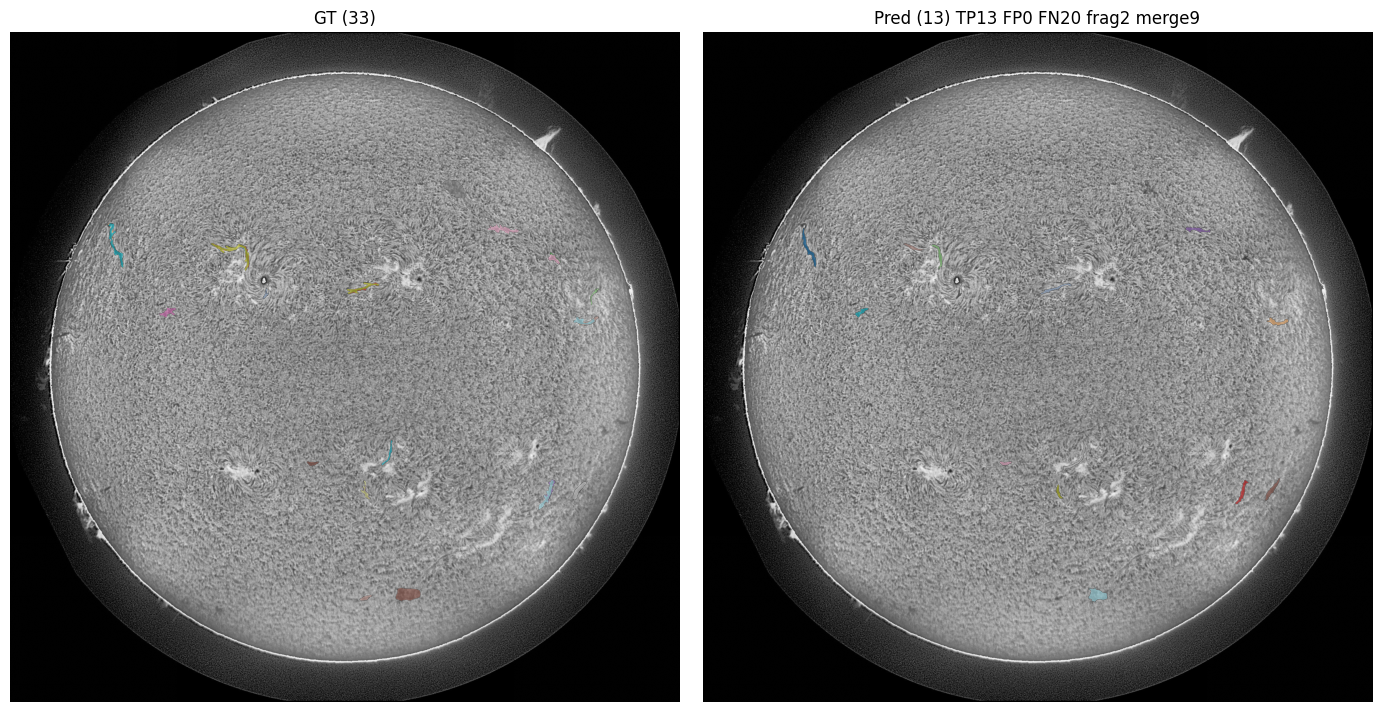

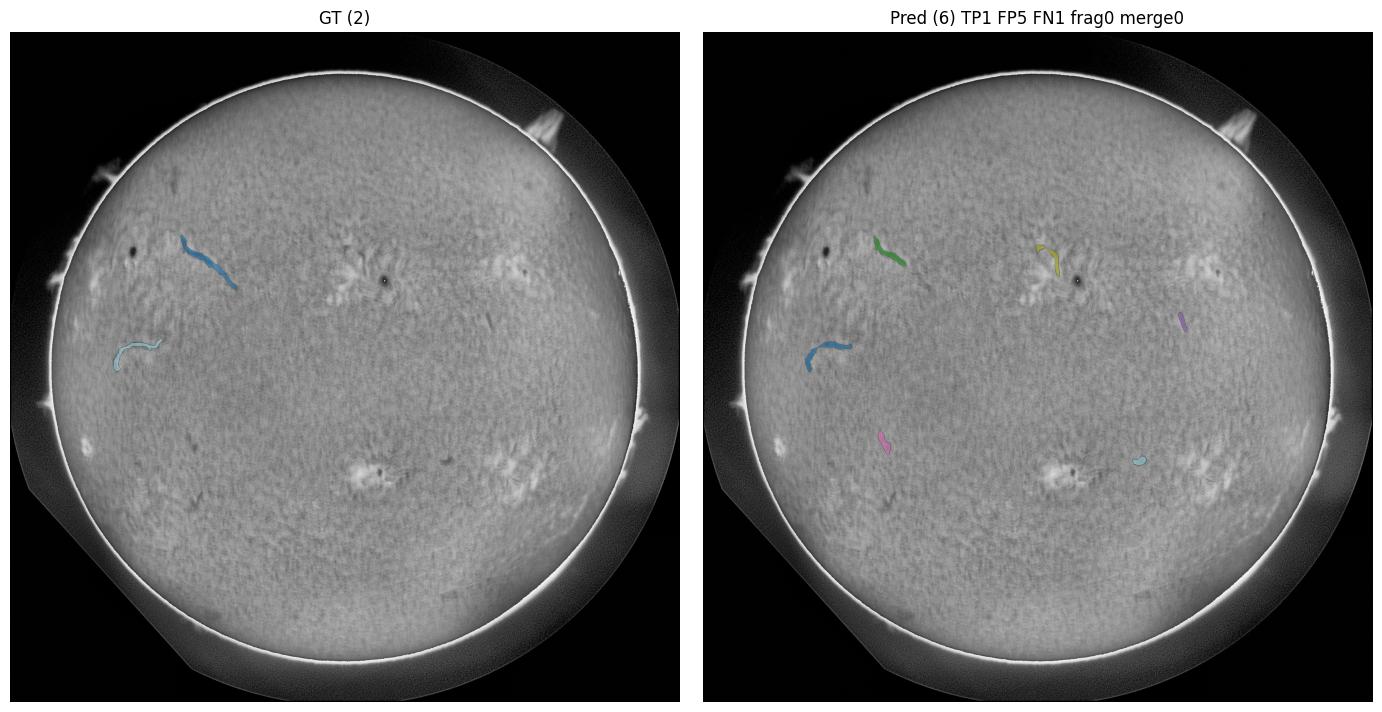

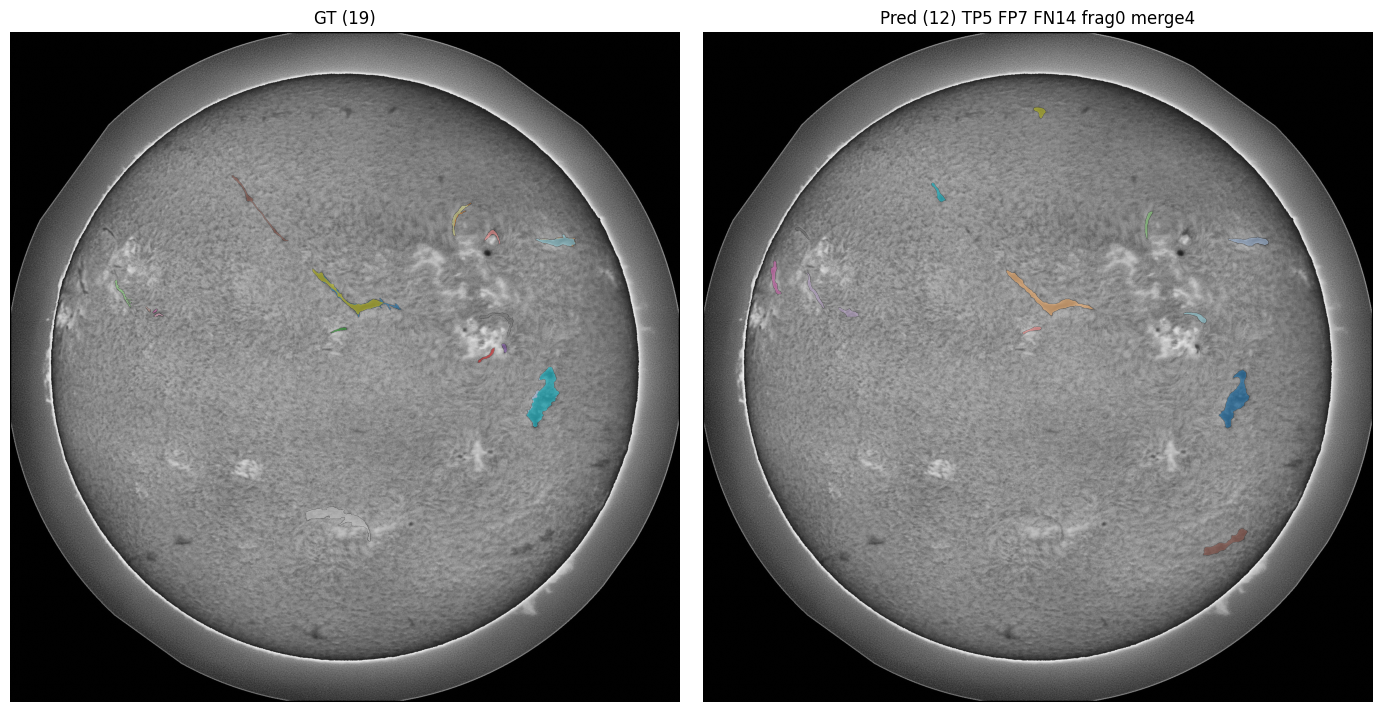

In [25]:
def rles_to_label(rles):
    out = np.zeros((IMG_SIZE, IMG_SIZE), np.int32)
    for i, r in enumerate(rles, 1): out[maskUtils.decode(r) > 0] = i
    return out

for s in [s for s in eval_stems_full if image_to_insts.get(s)][:3]:
    img = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s)); r = pq_image(get_gt_rles(s), preds[s])
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    for a, lb, t in ((ax[0], rles_to_label(get_gt_rles(s)), f"GT ({len(get_gt_rles(s))})"),
                     (ax[1], rles_to_label(preds[s]), f"Pred ({len(preds[s])}) TP{r['tp']} FP{r['fp']} FN{r['fn']} frag{r['frag']} merge{r['merge']}")):
        a.imshow(img, cmap="gray"); a.imshow(np.ma.masked_equal(lb, 0), cmap="tab20", alpha=0.6); a.set_title(t); a.axis("off")
    plt.tight_layout(); plt.show()


### Quick check: are the masks systematically too thin or too thick?
Many matches fail only because IoU lands just under 0.5. This prints the predicted/ground-truth area ratio and re-scores the full validation set after growing or shrinking every selected mask by a few pixels (cached detections, no GPU). It sets `MASK_ADJUST` only if the gain is above 0.005; the test-inference cell then applies it.

In [26]:
# ---- Are the predicted masks systematically too thin or too thick?  (cached detections, no GPU, ~2 min)
# Many matches fail only because IoU lands just under 0.5; a consistent bias in mask size is a cheap thing to fix.
base_preds = {s: select_instances(val_full_cache[s], *sel_args) for s in eval_stems_full}
ratios = []
for s in eval_stems_full:
    gts, preds = get_gt_rles(s), base_preds[s]
    if not gts or not preds: continue
    iou = np.array(maskUtils.iou(preds, gts, [0] * len(gts))).reshape(len(preds), len(gts))
    aP, aG = np.array(maskUtils.area(preds), float), np.array(maskUtils.area(gts), float)
    for p in range(len(preds)):
        g_ = int(iou[p].argmax())
        if iou[p, g_] > 0.3: ratios.append(aP[p] / aG[g_])
rt = np.array(ratios)
print(f"predicted / ground-truth area over {len(rt)} overlapping pairs: median {np.median(rt):.2f}, 25-75% {np.quantile(rt, .25):.2f}-{np.quantile(rt, .75):.2f}   (<1: masks too small, >1: too big)")

res = {}
for k in (-3, -2, -1, 0, 1, 2, 3, 4):
    r = eval_preds(eval_stems_full, {s: adjust_sel(base_preds[s], k, BEST_CFG["min_area"]) for s in eval_stems_full})
    res[k] = r["pq"]; print(f"grow/shrink {k:+d}px: PQ={r['pq']:.4f}  TP={r['tp']} FP={r['fp']} FN={r['fn']}")
best_k = max(res, key=res.get)
MASK_ADJUST = best_k if res[best_k] > res[0] + 0.005 else 0
print(f"\nMASK_ADJUST = {MASK_ADJUST}  ({'used by the test-inference cell' if MASK_ADJUST else 'no clear gain, left at 0'})")


predicted / ground-truth area over 543 overlapping pairs: median 1.00, 25-75% 0.81-1.19   (<1: masks too small, >1: too big)
grow/shrink -3px: PQ=0.1264  TP=164 FP=465 FN=766
grow/shrink -2px: PQ=0.2262  TP=295 FP=402 FN=635
grow/shrink -1px: PQ=0.3525  TP=433 FP=273 FN=497
grow/shrink +0px: PQ=0.3751  TP=449 FP=257 FN=481
grow/shrink +1px: PQ=0.3592  TP=439 FP=267 FN=491
grow/shrink +2px: PQ=0.3027  TP=388 FP=318 FN=542
grow/shrink +3px: PQ=0.2494  TP=331 FP=375 FN=599
grow/shrink +4px: PQ=0.1786  TP=244 FP=462 FN=686

MASK_ADJUST = 0  (no clear gain, left at 0)


### Is preprocessing a bottleneck? (Retinex vs CLAHE) — two cheap checks before retraining anything
**1.** Where are filaments missed relative to the solar disk? Retinex-style illumination correction only makes sense if misses pile up near the limb. **2.** A pixel-level proxy: how well does each preprocessing separate filament pixels from nearby background, plus a side-by-side preview. If both checks say it matters, set `PREPROC = "msr"` in the config cell, restart, and retrain with the usual cells (it uses its own work folder, so nothing is overwritten) — then compare full-validation PQ.

In [27]:
# ---- Where, relative to the solar disk, are filaments missed?  Illumination fixes (Retinex etc.) only make sense if misses concentrate near the limb.
def match_flags(gts, preds, thr=0.5):
    G, P = len(gts), len(preds); flags = np.zeros(G, bool)
    if G == 0 or P == 0: return flags
    iou = np.array(maskUtils.iou(preds, gts, [0] * G)).reshape(P, G)
    pairs = sorted(((iou[p, g], p, g) for p in range(P) for g in range(G) if iou[p, g] > thr), reverse=True)
    up, ug = set(), set()
    for v, p, g in pairs:
        if p in up or g in ug: continue
        up.add(p); ug.add(g); flags[g] = True
    return flags

bins = [(0.0, 0.4), (0.4, 0.7), (0.7, 0.85), (0.85, 1.5)]
stat = {b: [0, 0] for b in bins}                                   # [ground-truth filaments, found one-to-one at IoU>0.5]
for s in eval_stems_full:
    gts = get_gt_rles(s)
    if not gts: continue
    fl = match_flags(gts, select_instances(val_full_cache[s], *sel_args))
    for (x, y, w, h), f in zip(maskUtils.toBbox(gts), fl):
        r = np.hypot(x + w / 2 - IMG_SIZE / 2, y + h / 2 - IMG_SIZE / 2) / (IMG_SIZE / 2)
        for b in bins:
            if b[0] <= r < b[1]: stat[b][0] += 1; stat[b][1] += int(f)
print("distance of the filament from the disk centre (1.0 = image edge) | filaments | found | recall")
for b, (n, k) in stat.items(): print(f"   {b[0]:.2f}-{min(b[1], 1.0):.2f}            {n:>6}   {k:>5}   {k / max(n, 1):.0%}")
print("\nIf recall drops sharply in the outer rings, illumination correction is promising; if it is roughly flat, preprocessing is not your bottleneck.")

distance of the filament from the disk centre (1.0 = image edge) | filaments | found | recall
   0.00-0.40               276     148   54%
   0.40-0.70               510     231   45%
   0.70-0.85               144      70   49%
   0.85-1.00                 0       0   0%

If recall drops sharply in the outer rings, illumination correction is promising; if it is roughly flat, preprocessing is not your bottleneck.


preprocessing check:   0%|          | 0/40 [00:00<?, ?it/s]

40 images | per-image AUC of filament pixels vs nearby background (higher = easier to separate)
   raw        mean 0.796   vs clahe: -0.029 ± 0.005 (s.e.)
   clahe      mean 0.826   vs clahe: +0.000 ± 0.000 (s.e.)
   msr        mean 0.816   vs clahe: -0.010 ± 0.002 (s.e.)
   msr+clahe  mean 0.815   vs clahe: -0.010 ± 0.002 (s.e.)


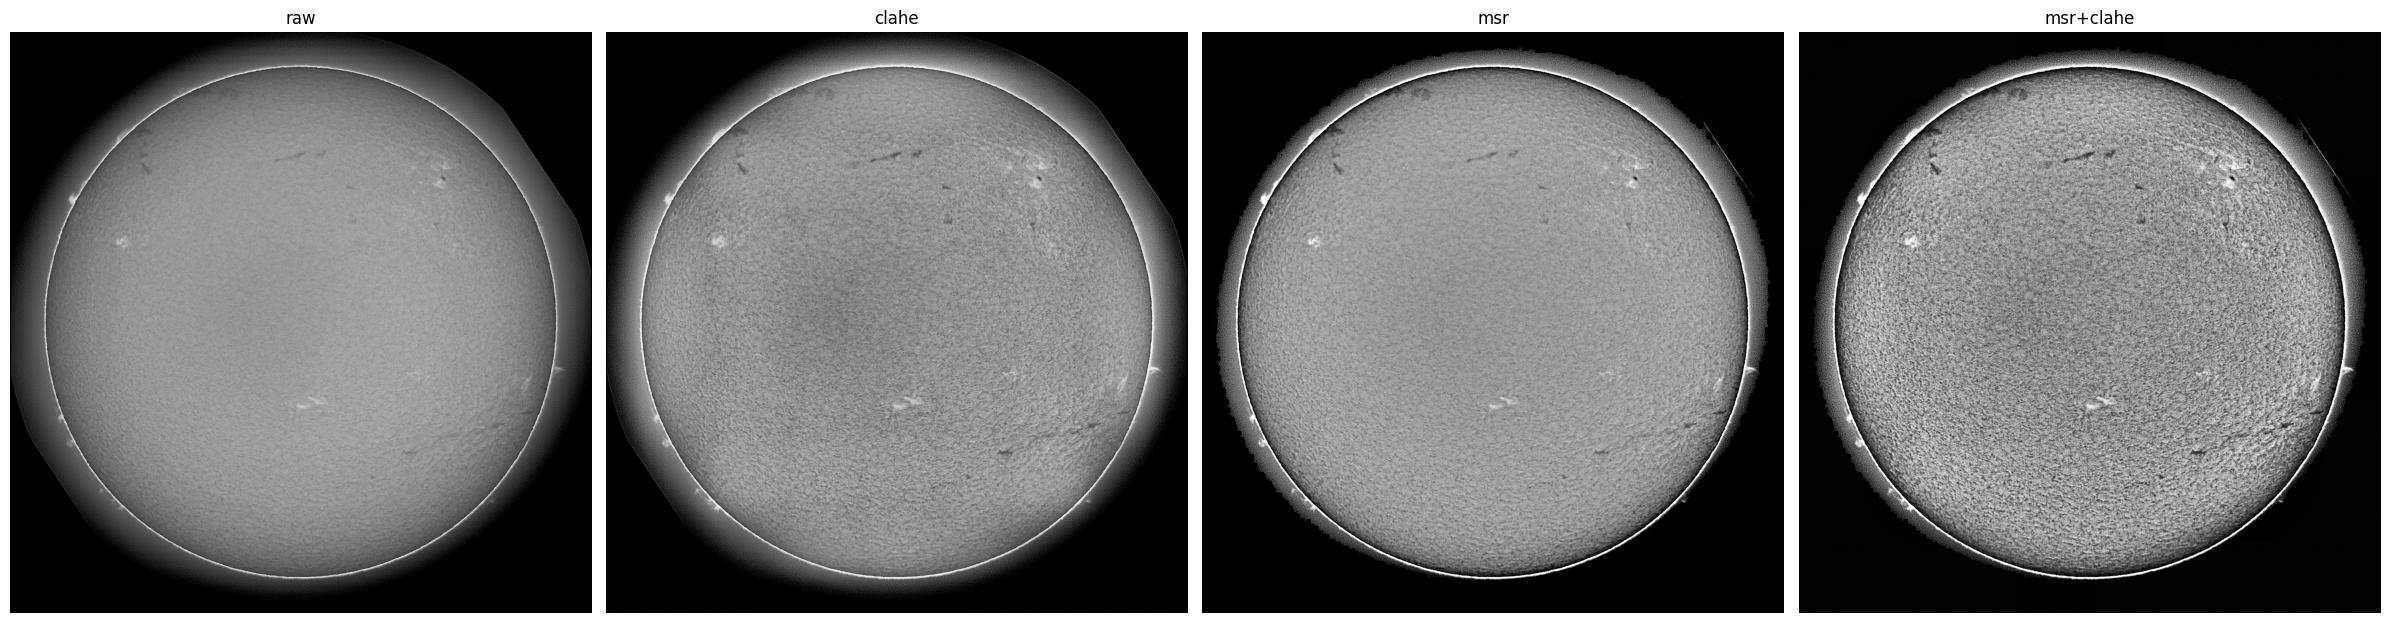

In [28]:
# ---- Cheap check BEFORE retraining anything: does Retinex separate filament pixels from nearby background better than CLAHE?
# Per image: AUC of "darker = filament" between filament pixels and a ring of background 4-40 px around them (inside the solar disk). 0.5 = no separation.
# It is a crude, pixel-level proxy (a network also uses context), so only a clear gap is worth acting on.
from sklearn.metrics import roc_auc_score
variants = {"raw": lambda im: im, "clahe": clahe_uint8, "msr": msr_uint8, "msr+clahe": lambda im: clahe_uint8(msr_uint8(im))}
k_out = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (81, 81)); k_in = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
rng_ = np.random.default_rng(0); aucs = {k: [] for k in variants}
for s in tqdm(random.Random(0).sample(train_stems, min(40, len(train_stems))), desc="preprocessing check"):
    insts = image_to_insts.get(s, [])
    if not insts: continue
    gt = np.maximum.reduce([seg_to_mask(sg) for sg in insts])
    raw = np.array(Image.open(resolve_img_path(TRAIN_IMG_DIR, s)).convert("L"))
    disk = raw > cv2.threshold(raw, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0]
    ring = (cv2.dilate(gt, k_out) > 0) & (cv2.dilate(gt, k_in) == 0) & disk
    pos, neg = np.flatnonzero(gt > 0), np.flatnonzero(ring)
    if len(pos) < 50 or len(neg) < 50: continue
    pos, neg = rng_.choice(pos, min(len(pos), 4000), replace=False), rng_.choice(neg, min(len(neg), 4000), replace=False)
    yy, idx = np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos, neg]
    for name, fn in variants.items():
        aucs[name].append(roc_auc_score(yy, -fn(raw).ravel()[idx].astype(np.float32)))
n_ok = len(aucs["clahe"])
print(f"{n_ok} images | per-image AUC of filament pixels vs nearby background (higher = easier to separate)")
for name, a in aucs.items():
    d = np.array(a) - np.array(aucs["clahe"])
    print(f"   {name:<10} mean {np.mean(a):.3f}   vs clahe: {d.mean():+.3f} ± {d.std() / max(np.sqrt(len(d)), 1):.3f} (s.e.)")

s_ = next(s for s in train_stems if len(image_to_insts.get(s, [])) >= 4)
raw = np.array(Image.open(resolve_img_path(TRAIN_IMG_DIR, s_)).convert("L"))
fig, ax = plt.subplots(1, 4, figsize=(24, 6.5))
for a, (name, fn) in zip(ax, variants.items()): a.imshow(fn(raw), cmap="gray"); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

### Where are the missed filaments? (run after the tuning cells)
Sorts every ground-truth filament into: matched / found but lost in selection / found with a poor mask / never detected, split by size. The row that dominates tells you what to fix next.

In [29]:
# ---- WHERE ARE THE MISSED FILAMENTS?  (uses det_cache + BEST_CFG from the tuning cells; no GPU, ~1 min)
key = BEST_CFG["key"]
def best_iou(rles, g):
    if not rles: return 0.0
    return float(np.array(maskUtils.iou(rles, [g], [0])).reshape(len(rles), 1).max())

recs, gain = [], []
for s in sweep_stems:
    gts = get_gt_rles(s)
    if not gts: continue
    pool = [c[key] for c in det_cache[s] if c.get(key) is not None]
    cpool = [c["coarse"] for c in det_cache[s]]
    sel = select_instances(det_cache[s], key, BEST_CFG["score_thr"], BEST_CFG["nms_thr"], BEST_CFG["min_area"])
    for g in gts:
        bs, bp, bc = best_iou(sel, g), best_iou(pool, g), best_iou(cpool, g)
        cat = ("matched" if bs > 0.5 else "in pool, lost in selection" if bp > 0.5
               else "pool IoU 0.3-0.5 (poor mask/box)" if bp > 0.3 else "never detected")
        recs.append((int(maskUtils.area(g)), cat))
        if max(bp, bc) > 0.3: gain.append(bp - bc)

q1, q2 = np.quantile([a for a, _ in recs], [1 / 3, 2 / 3])
print(f"GT instances: {len(recs)}   (size terciles split at {q1:.0f} and {q2:.0f} px)")
for name, lo, hi in (("small", 0, q1), ("mid", q1, q2), ("large", q2, 1e9)):
    sub = [c for a, c in recs if lo <= a < hi]
    print(f"\n{name}: {len(sub)}")
    for k in ("matched", "in pool, lost in selection", "pool IoU 0.3-0.5 (poor mask/box)", "never detected"):
        print(f"   {k:<34} {sub.count(k):>4}  ({100 * sub.count(k) / max(len(sub), 1):.0f}%)")
print(f"\nrefined minus coarse best-IoU, over detectable GT: mean {np.mean(gain):+.3f}")


GT instances: 412   (size terciles split at 796 and 1664 px)

small: 137
   matched                              85  (62%)
   in pool, lost in selection           35  (26%)
   pool IoU 0.3-0.5 (poor mask/box)      7  (5%)
   never detected                       10  (7%)

mid: 137
   matched                              98  (72%)
   in pool, lost in selection           16  (12%)
   pool IoU 0.3-0.5 (poor mask/box)     21  (15%)
   never detected                        2  (1%)

large: 138
   matched                              89  (64%)
   in pool, lost in selection           23  (17%)
   pool IoU 0.3-0.5 (poor mask/box)     25  (18%)
   never detected                        1  (1%)

refined minus coarse best-IoU, over detectable GT: mean +0.005


### Upgrade: re-train the refiner on the detector's **real** outputs
The first refiner learned from simulated coarse masks (IoU ≈ 0.91 with GT) but real Mask R-CNN masks are much worse, so it barely helped. This cell fine-tunes it on real detector outputs matched to ground truth. Run it, then **re-run the two tuning cells** and compare refined PQ with before. If the diagnostic above says most misses are "never detected", this will not help much — fix the detector instead.

In [30]:
# ---- RE-TRAIN THE REFINER ON THE DETECTOR'S REAL OUTPUTS (instead of simulated coarse masks)
# Samples are built exactly like at inference: detector candidate -> window -> [image, its coarse mask, other candidates];
# target = the ground-truth filament it overlaps most. Fine-tunes from ref_best.pt, saves ref2_best.pt.
import pickle
REF2_EPOCHS, REF2_LR, REF2_MIN_IOU = 6, 1e-4, 0.3
ref2_best_path, ref2_resume_path = WORK_DIR / "ref2_best.pt", WORK_DIR / "ref2_resume.pt"
if RETRAIN_REF:
    for p in (ref2_best_path, ref2_resume_path): p.unlink(missing_ok=True)

load_best_models()                                    # detector (best) in inference mode
det_tag = int(det_best_path.stat().st_mtime)
tr_path = WORK_DIR / f"cache_traindet_{det_tag}.pkl"
if tr_path.exists() and not RECOMPUTE_CACHE:
    train_det = pickle.load(open(tr_path, "rb")); print("loaded detections on train images")
else:
    train_det = {s: detect_candidates(det, load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s))) for s in tqdm(train_stems, desc="detecting on train images")}
    tmp = tr_path.with_suffix(".tmp"); pickle.dump(train_det, open(tmp, "wb"), protocol=4); tmp.replace(tr_path)
val_det = det_cache if "det_cache" in globals() else {s: detect_candidates(det, load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s))) for s in sweep_stems}

class RealRefDataset(Dataset):
    def __init__(self, stems, det_by_stem, train=True):
        self.stems = [s for s in stems if image_to_insts.get(s) and det_by_stem.get(s)]
        self.det, self.train = det_by_stem, train
    def __len__(self): return len(self.stems)
    def __getitem__(self, i):
        if not self.train: random.seed(1234 + i)
        stem = self.stems[i]; cands = self.det[stem]; gts = get_gt_rles(stem)
        img = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, stem)); H, W = img.shape
        coarse = [np.ascontiguousarray(maskUtils.decode(c["coarse"])) for c in cands]
        iou = np.array(maskUtils.iou([c["coarse"] for c in cands], gts, [0] * len(gts))).reshape(len(cands), len(gts))
        cnt = np.zeros((H, W), np.uint8)
        for c, m in zip(cands, coarse):
            if c["score"] >= CTX_SCORE: cnt += m
        idx = [k for k in range(len(cands)) if iou[k].max() >= REF2_MIN_IOU]; random.shuffle(idx)
        Xs, Ys = [], []
        for k in idx[:REF_K]:
            bb = bbox_of(coarse[k])
            if bb is None: continue
            gt = maskUtils.decode(gts[int(iou[k].argmax())])
            margin = random.randint(*REF_MARGIN) if self.train else REF_MARGIN_INFER
            wx0, wy0, L = window_for_box(bb, margin)
            cr = lambda a: crop_resize(a, wx0, wy0, L, REF_SIZE)
            others = ((cnt - coarse[k]) > 0) if cands[k]["score"] >= CTX_SCORE else (cnt > 0)
            arr = np.stack([cr(img).astype(np.float32) / 255.0, cr(coarse[k].astype(np.float32)),
                            cr(others.astype(np.float32)), cr(gt.astype(np.float32))])
            if self.train:
                arr = np.rot90(arr, random.randint(0, 3), axes=(1, 2))
                if random.random() < 0.5: arr = arr[:, :, ::-1]
                arr = np.ascontiguousarray(arr)
                arr[0] = np.clip(arr[0] * random.uniform(0.85, 1.15) + random.uniform(-0.04, 0.04), 0, 1)
            Xs.append(arr[:3]); Ys.append(arr[3:4])
        if not Xs:
            Xs, Ys = [np.zeros((3, REF_SIZE, REF_SIZE), np.float32)], [np.zeros((1, REF_SIZE, REF_SIZE), np.float32)]
        return torch.from_numpy(np.stack(Xs)), torch.from_numpy(np.stack(Ys))

real_loader = DataLoader(RealRefDataset(train_stems, train_det, True), batch_size=REF_BATCH_IMAGES, shuffle=True, num_workers=2,
                         collate_fn=ref_collate, drop_last=True, persistent_workers=True, pin_memory=True)
real_val_loader = DataLoader(RealRefDataset(sweep_stems, val_det, False), batch_size=REF_BATCH_IMAGES, shuffle=False, num_workers=2, collate_fn=ref_collate)

ref.load_state_dict(torch.load(ref_best_path, map_location=device))      # warm start from the simulated-mask refiner
opt2 = torch.optim.AdamW(ref.parameters(), lr=REF2_LR, weight_decay=1e-4)
sched2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=REF2_EPOCHS, eta_min=1e-6)
scaler2 = torch.amp.GradScaler("cuda", enabled=USE_AMP)
best2, start2 = -1.0, 1
if ref2_resume_path.exists():
    ck = torch.load(ref2_resume_path, map_location=device)
    ref.load_state_dict(ck["model"]); opt2.load_state_dict(ck["opt"]); sched2.load_state_dict(ck["sched"]); start2, best2 = ck["epoch"] + 1, ck["best"]
    print(f"resuming refiner-2 after epoch {ck['epoch']}")
if start2 > REF2_EPOCHS: print("refiner-2 already trained -> skipping")

for epoch in range(start2, REF2_EPOCHS + 1):
    ref.train(); run = 0.0
    for xb, yb in tqdm(real_loader, desc=f"ref2 epoch {epoch}/{REF2_EPOCHS}", leave=False):
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        opt2.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            loss = ref_loss(ref(xb).float(), yb)
        scaler2.scale(loss).backward(); scaler2.step(opt2); scaler2.update(); run += loss.item()
    sched2.step(); ref.eval(); i_in, i_out, cnt_ = 0.0, 0.0, 0
    with torch.no_grad():
        for xb, yb in real_val_loader:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                pr = torch.sigmoid(ref(xb).float())
            i_in += batch_iou(xb[:, 1:2], yb).sum().item(); i_out += batch_iou(pr, yb).sum().item(); cnt_ += len(xb)
    print(f"ref2 epoch {epoch:>2} | loss {run / len(real_loader):.4f} | val IoU on REAL detector masks: coarse {i_in / cnt_:.4f} -> refined {i_out / cnt_:.4f}")
    if i_out / cnt_ > best2:
        best2 = i_out / cnt_; torch.save(ref.state_dict(), ref2_best_path); print("   -> new best, saved")
    torch.save(dict(model=ref.state_dict(), opt=opt2.state_dict(), sched=sched2.state_dict(), epoch=epoch, best=best2), ref2_resume_path)

USE_REF2 = True        # from now on the pipeline uses ref2_best.pt. Re-run the tuning cells to compare against the old refiner (caches refresh automatically).
print("USE_REF2 = True -> re-run the two tuning cells, then full validation")


detecting on train images:   0%|          | 0/620 [00:00<?, ?it/s]

resuming refiner-2 after epoch 6
refiner-2 already trained -> skipping
USE_REF2 = True -> re-run the two tuning cells, then full validation


### Upgrade: learned candidate re-scorer
The detector produces ~33 candidates per image for ~10 real filaments, and its own score is only a mediocre way to pick which to keep (42% of kept predictions are false positives). This trains a small gradient-boosted model on *validation* candidates (the detector never trained on them) using shape, overlap-with-other-candidates and image-contrast features, and scores it **out-of-fold by image**, so the comparison with the detector score is honest. Run it after the tuning cells.

In [31]:
# ---- LEARNED RE-SCORER: predict "will this candidate match a ground-truth filament?" from shape / overlap / contrast features.
# Trained on VALIDATION candidates (the detector never saw them), scored out-of-fold by image, so the comparison is honest.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
N_FEAT = 15

def cand_features(img, cands):
    n = len(cands); H, W = img.shape
    if n == 0: return np.zeros((0, N_FEAT), np.float32)
    rl = [c["coarse"] for c in cands]; sc = np.array([c["score"] for c in cands], np.float32)
    area = np.array(maskUtils.area(rl), np.float32)
    ci = np.array(maskUtils.iou(rl, rl, [0] * n)).reshape(n, n); np.fill_diagonal(ci, 0)
    rank = (-sc).argsort().argsort(); n_conf = int((sc >= 0.5).sum())
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (13, 13))
    F = np.zeros((n, N_FEAT), np.float32)
    for i, c in enumerate(cands):
        x0, y0, x1, y1 = c["box"]; w, h = max(x1 - x0, 1.0), max(y1 - y0, 1.0)
        higher, ov = sc > sc[i], ci[i] > 0.3
        wx0, wy0, wx1, wy1 = max(int(x0) - 10, 0), max(int(y0) - 10, 0), min(int(x1) + 10, W), min(int(y1) + 10, H)
        m = np.ascontiguousarray(maskUtils.decode(rl[i])[wy0:wy1, wx0:wx1]); crop = img[wy0:wy1, wx0:wx1].astype(np.float32)
        inside = float(crop[m > 0].mean()) if m.any() else 0.0
        ring = cv2.dilate(m, ker) - m
        outside = float(crop[ring > 0].mean()) if (ring > 0).any() else inside
        F[i] = [sc[i], rank[i], n_conf, np.log1p(area[i]), np.log(max(w, h) / min(w, h)), max(w, h), area[i] / (w * h),
                ci[i][higher].max() if higher.any() else 0.0, int(ov.sum()), sc[ov].mean() if ov.any() else 0.0,
                int((ov & higher).sum()), outside - inside, inside,
                np.hypot((x0 + x1) / 2 - W / 2, (y0 + y1) / 2 - H / 2) / (W / 2), sc[i] - (sc[ov].max() if ov.any() else 0.0)]
    return F

def cand_labels(stem, cands):
    gts = get_gt_rles(stem)
    if not cands or not gts: return np.zeros(len(cands), bool)
    cg = np.array(maskUtils.iou([c["coarse"] for c in cands], gts, [0] * len(gts))).reshape(len(cands), len(gts))
    return cg.max(1) > 0.5

def make_rescorer():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, min_samples_leaf=20, random_state=SEED)


In [32]:
load_best_models(); TAG = ckpt_tag()
rs_val = get_cache(val_stems, TRAIN_IMG_DIR, "valall", "coarse", None, None)          # detections on ALL val images (cached on Drive)
Xs, ys, gs = [], [], []
for gi, s in enumerate(tqdm(val_stems, desc="features")):
    img = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s)); cs = rs_val[s]
    Xs.append(cand_features(img, cs)); ys.append(cand_labels(s, cs)); gs.append(np.full(len(cs), gi))
X, y, grp = np.concatenate(Xs), np.concatenate(ys), np.concatenate(gs)
print(f"{len(X)} candidates from {len(val_stems)} val images | {y.mean():.1%} match a GT filament (IoU>0.5)")

oof = np.zeros(len(X))
for tr, te in GroupKFold(n_splits=5).split(X, y, grp):
    oof[te] = make_rescorer().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
print(f"ranking quality (AUC): detector score alone {roc_auc_score(y, X[:, 0]):.3f} | re-scorer, out-of-fold {roc_auc_score(y, oof):.3f}")

rescored, pos = {}, 0
for s in val_stems:
    cs = rs_val[s]; rescored[s] = [{**c, "score": float(p)} for c, p in zip(cs, oof[pos:pos + len(cs)])]; pos += len(cs)

def sweep_sel(cache, thrs, tag):
    best = (-1.0, None, None)
    for thr in thrs:
        for nms in (0.0, 0.1, 0.2, 0.3):
            for ma in (100, 200):
                r = eval_cache(cache, val_stems, "coarse", thr, nms, ma)
                if r["pq"] > best[0]: best = (r["pq"], dict(score_thr=thr, nms_thr=nms, min_area=ma), r)
    print(f"{tag}: PQ={best[0]:.4f} {best[1]}  TP={best[2]['tp']} FP={best[2]['fp']} FN={best[2]['fn']}")
    return best
base_best = sweep_sel(rs_val, (0.4, 0.5, 0.6, 0.7), "detector score     ")
new_best = sweep_sel(rescored, (0.2, 0.3, 0.4, 0.5, 0.6), "re-scorer (out-of-fold)")


valall: detect + refine:   0%|          | 0/87 [00:00<?, ?it/s]

features:   0%|          | 0/87 [00:00<?, ?it/s]

3010 candidates from 87 val images | 37.9% match a GT filament (IoU>0.5)
ranking quality (AUC): detector score alone 0.687 | re-scorer, out-of-fold 0.812
detector score     : PQ=0.3676 {'score_thr': 0.7, 'nms_thr': 0.1, 'min_area': 200}  TP=446 FP=260 FN=484
re-scorer (out-of-fold): PQ=0.3634 {'score_thr': 0.3, 'nms_thr': 0.0, 'min_area': 200}  TP=441 FP=269 FN=489


**Only if the re-scorer line above beats the detector-score line by a clear margin**, run the next cell: it fits the model on all validation candidates, re-scores the test candidates and writes `submission_rescored.csv`. Then re-run the sanity-check cell (it asserts there are no overlapping masks) and the download cell.

In [33]:
# ---- Apply the re-scorer to the TEST set (only if it clearly beat the detector score above)
import pickle, pandas as pd
if new_best[0] <= base_best[0] + 0.005:
    print(f"re-scorer gain too small ({new_best[0]:.4f} vs {base_best[0]:.4f}) -> keeping the existing submission")
else:
    rescorer = make_rescorer().fit(X, y)                                        # fit on ALL val candidates
    pickle.dump(rescorer, open(WORK_DIR / "rescorer.pkl", "wb"))
    test_cache = get_cache(test_stems, TEST_IMG_DIR, "test", "coarse", None, None)
    p = new_best[1]; rows, empty = [], []
    for stem in tqdm(test_stems, desc="re-scoring test"):
        cs = test_cache[stem]
        if cs:
            pr = rescorer.predict_proba(cand_features(load_image_clahe(resolve_img_path(TEST_IMG_DIR, stem)), cs))[:, 1]
            cs = [{**c, "score": float(q)} for c, q in zip(cs, pr)]
        rles = select_instances(cs, "coarse", p["score_thr"], p["nms_thr"], p["min_area"])
        if not rles: empty.append(stem); continue
        for n, r in enumerate(rles, 1):
            c = r["counts"]; c = c.decode("utf-8") if isinstance(c, bytes) else c
            rows.append({"filament_id": f"{stem}_{n}", "segmentation_rle": c})
    submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    submission_path = WORK_DIR / "submission_rescored.csv"; submission.to_csv(submission_path, index=False)
    print(f"rows {len(submission)} | filaments/image {len(submission) / len(test_stems):.1f} | images with 0 predictions {len(empty)}")
    print("saved", submission_path.name, "-> now run the sanity-check cell and the download cell (they use `submission` / `submission_path`)")


re-scorer gain too small (0.3634 vs 0.3676) -> keeping the existing submission


### Optional: train a SECOND detector for an ensemble (~1 h, resumable)
Flip passes of one detector make correlated mistakes; a differently-built second model (Mask R-CNN v1, different seed) makes less correlated ones, so pooling both gives the consensus re-scorer more independent evidence. Skip this cell to test the single-detector TTA pool first. If you run it, **re-run the TTA helper cell and the TTA run cell afterwards** (detector 1's cached passes are reused; only the new ones are computed).

In [34]:
# ---- SECOND DETECTOR for the ensemble (optional, ~1 h on a T4; resumable). Different seed AND Mask R-CNN v1 (frozen BatchNorm, plain heads)
# so its mistakes are less correlated with detector 1. Its flipped passes are pooled with detector 1's in the TTA cells below.
DET2_ARCH, DET2_SEED, DET2_EPOCHS = "v1", 7, 8
det2_best_path, det2_resume_path = WORK_DIR / "det2_best.pt", WORK_DIR / "det2_resume.pt"
if RETRAIN_DET:
    for p in (det2_best_path, det2_resume_path): p.unlink(missing_ok=True)
def ckpt_arch(sd):                      # Mask R-CNN "v2" checkpoints have BatchNorm inside the FPN, "v1" ones do not
    return "v2" if any(k.startswith("backbone.fpn.inner_blocks.0.1.") for k in sd) else "v1"
if det2_resume_path.exists():           # a saved checkpoint decides the architecture (avoids "missing / unexpected keys" errors)
    _saved = ckpt_arch(torch.load(det2_resume_path, map_location="cpu")["model"])
    if _saved != DET2_ARCH:
        print(f"saved detector-2 checkpoint is a {_saved} model but DET2_ARCH={DET2_ARCH!r} -> using {_saved!r} to match it "
              f"(set RETRAIN_DET=True if you really want a different architecture)")
        DET2_ARCH = _saved
random.seed(DET2_SEED); torch.manual_seed(DET2_SEED)
det2 = build_detector(arch=DET2_ARCH).to(device)
det2_loader = DataLoader(DetDataset(train_stems), batch_size=DET_BATCH, shuffle=True, num_workers=2, collate_fn=det_collate,
                         drop_last=True, persistent_workers=True, pin_memory=True)
d2_params = [p for p in det2.parameters() if p.requires_grad]
d2_opt = torch.optim.AdamW(d2_params, lr=DET_LR, weight_decay=1e-4)
d2_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
d2_total = DET2_EPOCHS * len(det2_loader); d2_warm = max(1, min(100, d2_total // 5)); d2_it = 0
d2_best, d2_start = -1.0, 1
if det2_resume_path.exists():
    ck = torch.load(det2_resume_path, map_location=device)
    det2.load_state_dict(ck["model"]); d2_opt.load_state_dict(ck["opt"]); d2_start, d2_it, d2_best = ck["epoch"] + 1, ck["it"], ck["best"]
    print(f"resuming detector 2 after epoch {ck['epoch']} (best coarse PQ so far {d2_best:.4f})")
if d2_start > DET2_EPOCHS: print("detector 2 already trained -> skipping (set RETRAIN_DET=True to start over)")

for epoch in range(d2_start, DET2_EPOCHS + 1):
    det_train_mode(det2); tot = 0.0
    for n, (imgs, tgts) in enumerate(tqdm(det2_loader, desc=f"det2 epoch {epoch}/{DET2_EPOCHS}", leave=False), 1):
        lr = DET_LR * min(1.0, (d2_it + 1) / d2_warm) * 0.5 * (1 + math.cos(math.pi * d2_it / d2_total)); d2_it += 1
        for g_ in d2_opt.param_groups: g_["lr"] = lr
        imgs = [x.to(device, non_blocking=True) for x in imgs]
        tgts = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in tgts]
        d2_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            ld = det2(imgs, tgts); loss = sum(ld.values())
        d2_scaler.scale(loss).backward()
        d2_scaler.unscale_(d2_opt); torch.nn.utils.clip_grad_norm_(d2_params, 10.0)
        d2_scaler.step(d2_opt); d2_scaler.update(); tot += loss.item()
    det_infer_mode(det2)
    cache2 = {s: detect_candidates(det2, load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s))) for s in mon_stems}
    r = eval_cache(cache2, mon_stems, "coarse", 0.5, 0.7, 100)
    print(f"det2 epoch {epoch:>2} | loss {tot / len(det2_loader):.3f} | val coarse PQ {r['pq']:.4f} TP {r['tp']} FP {r['fp']} FN {r['fn']}")
    if r["pq"] > d2_best:
        d2_best = r["pq"]; torch.save(det2.state_dict(), det2_best_path); print("   -> new best, saved")
    torch.save(dict(model=det2.state_dict(), opt=d2_opt.state_dict(), epoch=epoch, it=d2_it, best=d2_best), det2_resume_path)
    torch.cuda.empty_cache()

def load_det2():
    det2.load_state_dict(torch.load(det2_best_path, map_location=device)); det_infer_mode(det2)

USE_DET2 = True      # the TTA helper cell below now pools detector 2's passes too (re-run it after this cell)
print("best detector-2 coarse PQ:", d2_best, "| USE_DET2 = True -> re-run the TTA helper cell and the TTA run cell")


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 187MB/s]


resuming detector 2 after epoch 8 (best coarse PQ so far 0.3061)
detector 2 already trained -> skipping (set RETRAIN_DET=True to start over)
best detector-2 coarse PQ: 0.3060620456286627 | USE_DET2 = True -> re-run the TTA helper cell and the TTA run cell


### Optional: a THIRD model family — YOLO11-seg (Ultralytics)
A different architecture from Mask R-CNN, so its mistakes are less correlated with yours; pooling it with the Mask R-CNN passes gives the consensus re-scorer more independent evidence. Starts from public COCO weights, trains on the full CLAHE images at 1280 px, resumable (checkpoints on Drive). Roughly 1 h on a T4 — skip it unless the flip-pooling result is promising. **After it finishes, re-run the TTA helper cell and the TTA run cell** (cached passes from your other models are reused; only YOLO's are computed). Ultralytics' training/predict calls follow its documented API but I could not run them here; if an argument is rejected by your installed version, remove it.

In [35]:
!pip install -q ultralytics


In [36]:
# ---- THIRD MODEL FAMILY: YOLO11-seg (Ultralytics). Different architecture from Mask R-CNN, trains fast, starts from public COCO weights.
# (Ultralytics code is AGPL-3.0, an OSI-approved licence; mention it and pin the version in your report/requirements.)
import shutil
from ultralytics import YOLO

YOLO_MODEL, YOLO_IMGSZ, YOLO_EPOCHS, YOLO_BATCH = "yolo11s-seg.pt", 1280, 40, 4   # imgsz 1280 = 0.62x native; use 1024 if slow or out of memory
RETRAIN_YOLO = False
YOLO_DIR = Path(f"/content/yolo_data_{PREPROC}")                                          # rebuilt each session from the CLAHE images (a few minutes)
yolo_run_dir = WORK_DIR / "yolo" / "run"
yolo_best_path, yolo_last_path, yolo_csv = yolo_run_dir / "weights" / "best.pt", yolo_run_dir / "weights" / "last.pt", yolo_run_dir / "results.csv"
YOLO_FLIPS = ("id", "h", "v", "hv")

def merge_parts(parts):
    """Several polygon parts of ONE filament -> one polygon (parts are joined by zero-width seams, as Ultralytics does for COCO)."""
    poly = parts[0]
    for p in parts[1:]:
        d = ((poly[:, None, :] - p[None, :, :]) ** 2).sum(-1); a, b = np.unravel_index(d.argmin(), d.shape)
        loop = np.concatenate([p[b:], p[:b + 1]])                 # walk once around the part, starting and ending at its nearest vertex
        poly = np.concatenate([poly[:a + 1], loop, poly[a:]])
    return poly

def instance_parts(seg):
    if isinstance(seg, dict):
        cs, _ = cv2.findContours(np.ascontiguousarray(seg_to_mask(seg)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        return [c[:, 0, :].astype(np.float64) for c in cs if len(c) >= 3]
    return [np.asarray(p, np.float64).reshape(-1, 2) for p in seg if len(p) >= 6]

def build_yolo_dataset():
    for split, stems in (("train", train_stems), ("val", sweep_stems)):
        (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True); (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)
        for s in tqdm(stems, desc=f"yolo data ({split})"):
            ip = YOLO_DIR / "images" / split / f"{s}.jpg"
            if not ip.exists(): cv2.imwrite(str(ip), load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s)), [cv2.IMWRITE_JPEG_QUALITY, 95])
            lines = []
            for seg in image_to_insts.get(s, []):                  # overlapping filaments are kept as separate instances
                parts = instance_parts(seg)
                if not parts: continue
                poly = np.clip(merge_parts(parts) / IMG_SIZE, 0, 1)
                if len(poly) >= 3: lines.append("0 " + " ".join(f"{v:.5f}" for v in poly.ravel()))
            (YOLO_DIR / "labels" / split / f"{s}.txt").write_text("\n".join(lines))
    (YOLO_DIR / "data.yaml").write_text(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: filament\n")

def _np(x): return x.cpu().numpy() if hasattr(x, "cpu") else np.asarray(x)

def detect_pass_yolo(model, img, flip):
    """One YOLO pass on a (possibly flipped) image -> candidates in ORIGINAL coordinates, src = 'y_' + flip."""
    H, W = img.shape
    im3 = np.ascontiguousarray(np.stack([flip_img(img, flip)] * 3, -1))
    r = model.predict(im3, imgsz=YOLO_IMGSZ, conf=0.05, iou=0.6, max_det=150, retina_masks=True,
                      device=0 if torch.cuda.is_available() else "cpu", verbose=False)[0]
    if r.masks is None or len(r.masks) == 0: return []
    masks, boxes, conf = _np(r.masks.data) > 0.5, _np(r.boxes.xyxy), _np(r.boxes.conf)
    out = []
    for m, b, c in zip(masks, boxes, conf):
        m = m.astype(np.uint8)
        if m.shape != (H, W): m = cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST)
        if not m.any(): continue
        m, box = unflip(m, [float(v) for v in b], flip, H, W)
        out.append(dict(box=box, score=float(c), mconf=float(c), src="y_" + flip, coarse=maskUtils.encode(np.asfortranarray(m))))
    return out

def load_yolo():
    global ymodel
    ymodel = YOLO(str(yolo_best_path))

build_yolo_dataset()
if RETRAIN_YOLO: shutil.rmtree(yolo_run_dir, ignore_errors=True)
done = yolo_best_path.exists() and yolo_csv.exists() and len(yolo_csv.read_text().strip().splitlines()) - 1 >= YOLO_EPOCHS
if done:
    print("YOLO already trained -> skipping (set RETRAIN_YOLO=True to start over)")
elif yolo_last_path.exists():
    print("resuming YOLO training from last.pt"); YOLO(str(yolo_last_path)).train(resume=True)
else:
    YOLO(YOLO_MODEL).train(data=str(YOLO_DIR / "data.yaml"), imgsz=YOLO_IMGSZ, epochs=YOLO_EPOCHS, batch=YOLO_BATCH, workers=2,
                           device=0 if torch.cuda.is_available() else "cpu", project=str(WORK_DIR / "yolo"), name="run", exist_ok=True,
                           overlap_mask=False, fliplr=0.5, flipud=0.5, degrees=0.0, seed=SEED, plots=False)
load_yolo()
USE_YOLO = True      # the TTA pool will now include YOLO's flipped passes -> re-run the TTA helper cell and the TTA run cell
print("YOLO ready (", yolo_best_path, ") | USE_YOLO = True")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


yolo data (train):   0%|          | 0/620 [00:00<?, ?it/s]

yolo data (val):   0%|          | 0/40 [00:00<?, ?it/s]

YOLO already trained -> skipping (set RETRAIN_YOLO=True to start over)
YOLO ready ( /content/drive/MyDrive/filament_work/yolo/run/weights/best.pt ) | USE_YOLO = True


### Upgrade (strongest): TTA pool + consensus re-scorer + mask fusion
Runs the detector(s) on 4 flipped copies of every image. A real filament is found by several passes, a spurious one usually is not, so *agreement between passes* is a much better "is this real?" signal than the detector score. The re-scorer (trained on validation, scored out-of-fold by image) uses it; then masks of agreeing passes are averaged to sharpen boundaries. The run cell compares: **A** single pass + detector score, **B** pooled + re-scorer, **C** pooled + re-scorer + fusion. First run: ~5 s per image per detector for val (87) and test (180), cached on Drive and saved every 25 images. Needs the **re-scorer helpers cell above** to have been run (it defines the feature functions).

In [37]:
# ---- TTA POOL + CONSENSUS: run the detector on flipped copies of every image. A real filament is found by several passes;
# a spurious one usually is not. Agreement between passes feeds the re-scorer, and averaging the masks of agreeing passes sharpens boundaries.
import pickle
PASSES1 = ("id", "h", "v", "hv")                     # detector 1: original + 3 flips
PASSES2 = ("id2", "h2", "v2", "hv2")                 # detector 2 (optional second model), same flips
PASSES3 = ("y_id", "y_h", "y_v", "y_hv")                # YOLO11-seg passes (optional third model family)
TTA_PASSES = PASSES1 + (PASSES2 if USE_DET2 else ()) + (PASSES3 if USE_YOLO else ())
N_FEAT2 = N_FEAT + 5

def flip_img(img, flip):
    if "h" in flip: img = img[:, ::-1]
    if "v" in flip: img = img[::-1]
    return np.ascontiguousarray(img)

def unflip(m, box, flip, H, W):
    """mask + box predicted on a flipped image -> original image coordinates."""
    x0, y0, x1, y1 = box
    if "h" in flip: m = m[:, ::-1]; x0, x1 = W - x1, W - x0
    if "v" in flip: m = m[::-1]; y0, y1 = H - y1, H - y0
    return m, [x0, y0, x1, y1]

@torch.no_grad()
def detect_pass(det, img, flip):
    """One detector pass on a (possibly flipped) image; candidates come back in ORIGINAL coordinates with their pass name."""
    H, W = img.shape
    x = torch.from_numpy(flip_img(img, flip).astype(np.float32) / 255.0).unsqueeze(0).repeat(3, 1, 1).to(device)
    with torch.autocast(device_type="cuda", enabled=USE_AMP):
        out = det([x])[0]
    boxes = out["boxes"].float().cpu().numpy(); scores = out["scores"].float().cpu().numpy()
    probs = out["masks"][:, 0].float(); binm = probs > 0.5
    mconf = ((probs * binm).sum((1, 2)) / binm.sum((1, 2)).clamp(min=1)).cpu().numpy()      # mean mask probability inside the mask
    masks = binm.cpu().numpy().astype(np.uint8)
    cands = []
    for b, s, m, mc in zip(boxes, scores, masks, mconf):
        if not m.any(): continue
        m, box = unflip(m, [float(v) for v in b], flip, H, W)
        cands.append(dict(box=box, score=float(s), mconf=float(mc), src=flip, coarse=maskUtils.encode(np.asfortranarray(m))))
    del out, x, probs, binm
    return cands

def build_pool_for(model, passes, stems, img_dir, fname, fn=None):
    """Candidates of every pass of ONE model for every image; cached on Drive, saved every 25 images (safe against disconnects)."""
    path = WORK_DIR / fname
    cache = pickle.load(open(path, "rb")) if (path.exists() and not RECOMPUTE_CACHE) else {}
    todo = [s for s in stems if s not in cache]
    for k, s in enumerate(tqdm(todo, desc=f"detecting {fname[:40]}")):
        img = load_image_clahe(resolve_img_path(img_dir, s))
        cache[s] = [c for f in passes for c in (fn or detect_pass)(model, img, f)]
        if (k + 1) % 25 == 0: save_pickle(cache, path)
    if todo: save_pickle(cache, path)
    return {s: cache[s] for s in stems}

def build_pool(stems, img_dir, name):
    pool = build_pool_for(det, PASSES1, stems, img_dir, f"cache_pool_{name}_{POOL_TAG}.pkl")
    if USE_DET2:
        p2 = build_pool_for(det2, PASSES2, stems, img_dir, f"cache_pool2_{name}_{POOL2_TAG}.pkl")
        pool = {s: pool[s] + p2[s] for s in stems}
    if USE_YOLO:
        p3 = build_pool_for(ymodel, YOLO_FLIPS, stems, img_dir, f"cache_pool3_{name}_{POOL3_TAG}.pkl", fn=detect_pass_yolo)
        pool = {s: pool[s] + p3[s] for s in stems}
    return pool

def pool_features(img, pool):
    """(N, N_FEAT2): the single-pass features (computed inside each pass) + 5 consensus features across passes."""
    n = len(pool); F = np.zeros((n, N_FEAT2), np.float32)
    if n == 0: return F
    srcs = np.array([c["src"] for c in pool])
    for f in TTA_PASSES:
        idx = np.flatnonzero(srcs == f)
        if len(idx): F[idx, :N_FEAT] = cand_features(img, [pool[i] for i in idx])
    rl = [c["coarse"] for c in pool]; sc = np.array([c["score"] for c in pool], np.float32)
    iou = np.array(maskUtils.iou(rl, rl, [0] * n)).reshape(n, n)
    for i in range(n):
        bi, bs = [], []
        for f in TTA_PASSES:
            if f == srcs[i]: continue
            idx = np.flatnonzero(srcs == f)
            if len(idx) == 0: bi.append(0.0); bs.append(0.0); continue
            j = idx[np.argmax(iou[i, idx])]
            bi.append(float(iou[i, j])); bs.append(float(sc[j]) if iou[i, j] > 0.5 else 0.0)
        bi, bs = np.array(bi), np.array(bs)
        F[i, N_FEAT:] = [(bi > 0.5).sum(), bi.mean(), bs.mean(), bs.max(), pool[i]["mconf"]]
    return F

def finalize(rles, min_area):
    """Kaggle forbids overlapping predictions: shared pixels go to the earlier (better) instance; tiny leftovers are dropped."""
    n = len(rles)
    if n == 0: return []
    if n == 1: return [r for r in rles if maskUtils.area(r) >= min_area]
    iou = np.array(maskUtils.iou(rles, rles, [0] * n)).reshape(n, n); np.fill_diagonal(iou, 0)
    touching = (iou > 0).any(1)
    free = [r for r, t in zip(rles, touching) if not t and maskUtils.area(r) >= min_area]
    return free + make_disjoint([r for r, t in zip(rles, touching) if t], min_area)

def select_fused(cands, thr, nms_thr, min_area, fuse=True):
    """cands = pooled candidates whose `score` may be the re-scorer's probability. NMS -> (optional) fuse masks across passes -> no-overlap."""
    order = [i for i in np.argsort([-c["score"] for c in cands]) if cands[i]["score"] >= thr and maskUtils.area(cands[i]["coarse"]) >= min_area]
    if not order: return []
    rl = [cands[i]["coarse"] for i in order]; n = len(rl)
    iou = np.array(maskUtils.iou(rl, rl, [0] * n)).reshape(n, n)
    keep = []
    for a in range(n):
        if all(iou[a, b] <= nms_thr for b in keep): keep.append(a)
    if not fuse: return finalize([rl[a] for a in keep], min_area)
    all_rl = [c["coarse"] for c in cands]; srcs = np.array([c["src"] for c in cands])
    iou_all = np.array(maskUtils.iou([rl[a] for a in keep], all_rl, [0] * len(all_rl))).reshape(len(keep), len(all_rl))
    fused = []
    for k, a in enumerate(keep):
        ci = order[a]; masks = [maskUtils.decode(all_rl[ci])]
        for f in TTA_PASSES:
            if f == cands[ci]["src"]: continue
            idx = np.flatnonzero(srcs == f)
            if len(idx) == 0: continue
            j = idx[np.argmax(iou_all[k, idx])]
            if iou_all[k, j] > 0.5: masks.append(maskUtils.decode(all_rl[j]))
        m = (np.sum(masks, 0, dtype=np.uint8) * 2 >= len(masks)).astype(np.uint8)        # pixel kept if at least half the passes agree
        fused.append(maskUtils.encode(np.asfortranarray(m)) if m.any() else all_rl[ci])
    return finalize(fused, min_area)


In [38]:
# ---- Build the TTA pool for the validation images, train the consensus re-scorer (out-of-fold by image), compare selection strategies
load_best_models()
if USE_DET2: load_det2()
if USE_YOLO: load_yolo()
POOL_TAG = f"{int(det_best_path.stat().st_mtime)}_{len(PASSES1)}"
POOL2_TAG = f"{int(det2_best_path.stat().st_mtime)}_{len(PASSES2)}" if USE_DET2 else ""
POOL3_TAG = f"{int(yolo_best_path.stat().st_mtime)}_{len(PASSES3)}" if USE_YOLO else ""
print("passes:", TTA_PASSES)
pool_val = build_pool(val_stems, TRAIN_IMG_DIR, "val")          # ~5 s per image per detector the first time, then cached on Drive

Xs, ys, gs = [], [], []
for gi, s in enumerate(tqdm(val_stems, desc="features")):
    img = load_image_clahe(resolve_img_path(TRAIN_IMG_DIR, s)); pl = pool_val[s]
    Xs.append(pool_features(img, pl)); ys.append(cand_labels(s, pl)); gs.append(np.full(len(pl), gi))
XP, yP, gP = np.concatenate(Xs), np.concatenate(ys), np.concatenate(gs)
print(f"{len(XP)} pass-candidates from {len(val_stems)} val images | {yP.mean():.1%} match a GT filament (IoU>0.5)")

oofP = np.zeros(len(XP))
for tr, te in GroupKFold(n_splits=5).split(XP, yP, gP):
    oofP[te] = make_rescorer().fit(XP[tr], yP[tr]).predict_proba(XP[te])[:, 1]
print(f"ranking quality (AUC): detector score {roc_auc_score(yP, XP[:, 0]):.3f} | consensus re-scorer (out-of-fold) {roc_auc_score(yP, oofP):.3f}")

rescored_pool, pos = {}, 0
for s in val_stems:
    pl = pool_val[s]; rescored_pool[s] = [{**c, "score": float(p)} for c, p in zip(pl, oofP[pos:pos + len(pl)])]; pos += len(pl)
single = {s: [c for c in pool_val[s] if c["src"] == "id"] for s in val_stems}

def eval_sel(fn, cache): return eval_preds(val_stems, {s: fn(cache[s]) for s in val_stems})
def show(tag, pq, p, r): print(f"{tag:<44} PQ={pq:.4f} {p}  TP={r['tp']} FP={r['fp']} FN={r['fn']}")

# A) baseline: one pass, detector score
bestA = (-1, None, None)
for thr in (0.4, 0.5, 0.6, 0.7):
    for nms in (0.0, 0.1, 0.2, 0.3):
        r = eval_sel(lambda cs: select_instances(cs, "coarse", thr, nms, 100), single)
        if r["pq"] > bestA[0]: bestA = (r["pq"], dict(thr=thr, nms=nms, min_area=100), r)
show("A  single pass, detector score", *bestA)

# B) all passes pooled, consensus re-scorer, no mask fusion
bestB = (-1, None, None)
for thr in (0.2, 0.3, 0.4, 0.5, 0.6):
    for nms in (0.1, 0.2, 0.3, 0.5):
        for ma in (100, 200):
            r = eval_sel(lambda cs: select_fused(cs, thr, nms, ma, fuse=False), rescored_pool)
            if r["pq"] > bestB[0]: bestB = (r["pq"], dict(thr=thr, nms=nms, min_area=ma, fuse=False), r)
show("B  pooled + re-scorer", *bestB)

# C) same + average the masks of agreeing passes
bestC = (-1, None, None)
for thr in sorted({max(0.1, bestB[1]["thr"] - 0.1), bestB[1]["thr"], bestB[1]["thr"] + 0.1}):
    p = dict(thr=thr, nms=bestB[1]["nms"], min_area=bestB[1]["min_area"], fuse=True)
    r = eval_sel(lambda cs: select_fused(cs, p["thr"], p["nms"], p["min_area"], True), rescored_pool)
    if r["pq"] > bestC[0]: bestC = (r["pq"], p, r)
show("C  pooled + re-scorer + mask fusion", *bestC)

tta_choice = max((bestA, "A"), (bestB, "B"), (bestC, "C"), key=lambda t: t[0][0])
print(f"\nbest strategy: {tta_choice[1]}  (PQ {tta_choice[0][0]:.4f}; A was {bestA[0]:.4f})")
json.dump(dict(strategy=tta_choice[1], params=tta_choice[0][1], pq=tta_choice[0][0], base=bestA[0]), open(WORK_DIR / "tta_choice.json", "w"))


passes: ('id', 'h', 'v', 'hv', 'id2', 'h2', 'v2', 'hv2', 'y_id', 'y_h', 'y_v', 'y_hv')


detecting cache_pool_val_1793263560_4.pkl:   0%|          | 0/87 [00:00<?, ?it/s]

detecting cache_pool2_val_1793273906_4.pkl:   0%|          | 0/87 [00:00<?, ?it/s]

detecting cache_pool3_val_1793277012_4.pkl:   0%|          | 0/87 [00:00<?, ?it/s]

features:   0%|          | 0/87 [00:00<?, ?it/s]

30795 pass-candidates from 87 val images | 38.8% match a GT filament (IoU>0.5)
ranking quality (AUC): detector score 0.667 | consensus re-scorer (out-of-fold) 0.826
A  single pass, detector score               PQ=0.3674 {'thr': 0.7, 'nms': 0.1, 'min_area': 100}  TP=446 FP=261 FN=484
B  pooled + re-scorer                        PQ=0.3746 {'thr': 0.5, 'nms': 0.1, 'min_area': 100, 'fuse': False}  TP=434 FP=196 FN=496
C  pooled + re-scorer + mask fusion          PQ=0.3870 {'thr': 0.5, 'nms': 0.1, 'min_area': 100, 'fuse': True}  TP=441 FP=190 FN=489

best strategy: C  (PQ 0.3870; A was 0.3674)


**Only if the best strategy printed above beats A clearly**, run the next cell. It writes `submission_tta.csv` and sets `submission` / `submission_path`. **Then skip the "Test inference" cell below** (it would overwrite `submission`) and run only the sanity-check and download cells.

In [39]:
# ---- Apply the best strategy to the TEST set (only if it clearly beats the single-pass baseline) -> submission_tta.csv
import pandas as pd
strategy, params = tta_choice[1], tta_choice[0][1]
if strategy == "A" or tta_choice[0][0] <= bestA[0] + 0.005:
    print(f"no clear gain over the single-pass baseline (best {tta_choice[0][0]:.4f} vs A {bestA[0]:.4f}) -> keep the existing submission")
else:
    rescorer_tta = make_rescorer().fit(XP, yP)                                   # fit on ALL validation pass-candidates
    pickle.dump(rescorer_tta, open(WORK_DIR / "rescorer_tta.pkl", "wb"))
    pool_test = build_pool(test_stems, TEST_IMG_DIR, "test")                      # ~5 s per image the first time, then cached
    rows, empty = [], []
    for stem in tqdm(test_stems, desc="re-scoring + selecting"):
        pl = pool_test[stem]
        if pl:
            pr = rescorer_tta.predict_proba(pool_features(load_image_clahe(resolve_img_path(TEST_IMG_DIR, stem)), pl))[:, 1]
            pl = [{**c, "score": float(q)} for c, q in zip(pl, pr)]
        rles = select_fused(pl, params["thr"], params["nms"], params["min_area"], params["fuse"])
        if not rles: empty.append(stem); continue
        for n, r in enumerate(rles, 1):
            c = r["counts"]; c = c.decode("utf-8") if isinstance(c, bytes) else c
            rows.append({"filament_id": f"{stem}_{n}", "segmentation_rle": c})
    submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    submission_path = WORK_DIR / "submission_tta.csv"; submission.to_csv(submission_path, index=False)
    print(f"strategy {strategy} {params} | rows {len(submission)} | filaments/image {len(submission) / len(test_stems):.1f} | images with 0 predictions {len(empty)}")
    print("saved", submission_path.name, "-> now run the sanity-check cell (asserts no overlapping masks) and the download cell")


detecting cache_pool_test_1793263560_4.pkl:   0%|          | 0/180 [00:00<?, ?it/s]

detecting cache_pool2_test_1793273906_4.pkl:   0%|          | 0/180 [00:00<?, ?it/s]

detecting cache_pool3_test_1793277012_4.pkl:   0%|          | 0/180 [00:00<?, ?it/s]

re-scoring + selecting:   0%|          | 0/180 [00:00<?, ?it/s]

strategy C {'thr': 0.5, 'nms': 0.1, 'min_area': 100, 'fuse': True} | rows 1403 | filaments/image 7.8 | images with 0 predictions 1
saved submission_tta.csv -> now run the sanity-check cell (asserts no overlapping masks) and the download cell


## 9. Test inference → `submission.csv`

In [40]:
assert submission["filament_id"].is_unique
assert not submission["segmentation_rle"].str.contains('"').any(), "RLE strings must not contain quotes"
covered = set(f.rsplit("_", 1)[0] for f in submission["filament_id"])
print("test images without any row:", len(set(test_stems) - covered), "/", len(test_stems))
for fid, c in list(zip(submission["filament_id"], submission["segmentation_rle"]))[:3]:
    print(fid, "mask pixels:", int(maskUtils.decode({"counts": c.encode("utf-8"), "size": [IMG_SIZE, IMG_SIZE]}).sum()))
by_img = defaultdict(list)
for fid, c in zip(submission["filament_id"], submission["segmentation_rle"]): by_img[fid.rsplit("_", 1)[0]].append(c)
n_bad = 0
for stem, cs in by_img.items():
    acc = np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    for c in cs: acc += maskUtils.decode({"counts": c.encode("utf-8"), "size": [IMG_SIZE, IMG_SIZE]})
    n_bad += int(acc.max() > 1)
print("images whose predicted masks overlap:", n_bad, "(must be 0, otherwise Kaggle rejects the file)")
assert n_bad == 0
print("train filaments/image: %.1f" % np.mean([len(image_to_insts.get(s, [])) for s in all_stems]), "(compare with your test filaments/image above)")


test images without any row: 1 / 180
20110120105534Ch_1 mask pixels: 1366
20110120105534Ch_2 mask pixels: 1179
20110120105534Ch_3 mask pixels: 375
images whose predicted masks overlap: 0 (must be 0, otherwise Kaggle rejects the file)
train filaments/image: 11.6 (compare with your test filaments/image above)


In [41]:
from google.colab import files
files.download(str(submission_path))
# or: !kaggle competitions submit -c filament-segmentation-2026 -f "{submission_path}" -m "v4 detector+refiner"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Reproducibility files (needed for final eligibility)

In [42]:
!pip freeze | grep -iE "^(torch|torchvision|pycocotools|numpy|pandas|opencv|pillow|matplotlib|kaggle|tqdm|ultralytics|scikit-learn)" > {WORK_DIR}/requirements.txt
!cat {WORK_DIR}/requirements.txt


kaggle==2.0.2
kagglehub==1.0.3
kagglesdk==0.1.38
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
numpy==2.1.3
opencv-contrib-python==4.14.0.94
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
pillow==11.3.0
pycocotools==2.0.11
scikit-learn==1.6.1
torch==2.11.0+cu130
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.11.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.26.0+cu130
tqdm==4.67.3
ultralytics==8.4.193
ultralytics-platform==0.1.101
ultralytics-thop==2.2.3


## What to try next (one change at a time, judged by full-val PQ)

1. **Compare coarse vs refined** in section 8. If refined is not clearly better, train the refiner longer / with larger `REF_SIZE`.
2. **More detector epochs** (`DET_EPOCHS = 14`) — the reference weights only used 6–8 epochs, but you have a different image count; watch whether val PQ is still rising.
3. Raise `DET_CROP` to 1536 (more context per crop) if memory allows, or `DET_ARCH="v1"` if training is unstable.
4. Horizontal-flip TTA for the detector + merge candidates with mask-IoU NMS.
5. Train on **train + val** for the final model once settings are fixed (keep the val numbers from the earlier run for the report).